In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import DBSCAN
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
from collections import defaultdict

## Parsowanie danych z plików

In [ ]:
data_path = "data"
all_vectors_dict = defaultdict(list)
all_points_dict = defaultdict(list)


In [ ]:
letter_map = {
    'a+': 'ą', 'c+': 'ć', 'e+': 'ę', 'l+': 'ł', 'n+': 'ń', 'o+': 'ó',
    's+': 'ś', 'z+': 'ź', 'z-': 'ż'
}

def map_letter(folder_name):
    return letter_map.get(folder_name, folder_name)

vector_pattern = re.compile(r'(\d+)[→\->](\d+): \((-?\d+\.\d+), (-?\d+\.\d+), (-?\d+\.\d+)\)')
point_pattern = re.compile(r"Punkt \d+: x=(-?\d+\.\d+), y=(-?\d+\.\d+), z=(-?\d+\.\d+)")

for letter_folder in sorted(os.listdir(data_path)):
    letter_path = os.path.join(data_path, letter_folder)
    if not os.path.isdir(letter_path):
        continue

    txt_file = os.path.join(letter_path, f"{letter_folder}.txt")
    if not os.path.isfile(txt_file):
        continue

    letter_name = map_letter(letter_folder)

    with open(txt_file, 'r', encoding='utf-8') as f:
        lines = f.readlines()

    current_vectors = []
    current_points = []
    in_vectors_block = False

    EXPECTED_VECTOR_COUNT = None 
    for line in lines:
        line = line.strip()

        if line.startswith("===="):
            if current_vectors:
                all_vectors_dict[letter_name].append(np.array(current_vectors).flatten())
                current_vectors = []
            if current_points:
                all_points_dict[letter_name].append(np.array(current_points).flatten())
                current_points = []
            in_vectors_block = False

        elif line.startswith("Wektory:"):
            in_vectors_block = True

        elif in_vectors_block and (match := vector_pattern.search(line)):
            x, y, z = float(match.group(3)), float(match.group(4)), float(match.group(5))
            current_vectors.append([x, y, z])

        elif not in_vectors_block and (match := point_pattern.search(line)):
            x, y, z = float(match.group(1)), float(match.group(2)), float(match.group(3))
            current_points.append([x, y, z])

    if current_vectors:
        if EXPECTED_VECTOR_COUNT is None:
            EXPECTED_VECTOR_COUNT = len(current_vectors)
        if len(current_vectors) == EXPECTED_VECTOR_COUNT:
            all_vectors_dict[letter_name].append(np.array(current_vectors).flatten())

    if current_points:
        all_points_dict[letter_name].append(np.array(current_points).flatten())
    
    from collections import Counter

    # Obliczamy najczęstszy rozmiar próbki
    vector_lengths = [len(v) for vectors in all_vectors_dict.values() for v in vectors]
    most_common_vector_len = Counter(vector_lengths).most_common(1)[0][0]

    # Filtrowanie wektorów
    filtered_vectors_dict = defaultdict(list)
    for letter, vectors in all_vectors_dict.items():
        for v in vectors:
            if len(v) == most_common_vector_len:
                filtered_vectors_dict[letter].append(v)
    all_vectors_dict = filtered_vectors_dict
    point_lengths = [len(p) for points in all_points_dict.values() for p in points]
    most_common_point_len = Counter(point_lengths).most_common(1)[0][0]

    filtered_points_dict = defaultdict(list)
    for letter, points in all_points_dict.items():
        for p in points:
            if len(p) == most_common_point_len:
                filtered_points_dict[letter].append(p)
    all_points_dict = filtered_points_dict
    

## Obliczanie średnich wektorów i punktów

In [4]:
mean_vectors_dict = {
    letter: np.mean(np.stack(vectors), axis=0)
    for letter, vectors in all_vectors_dict.items()
}

mean_points_dict = {
    letter: np.mean(np.stack(points), axis=0)
    for letter, points in all_points_dict.items()
}

mean_vectors_df = pd.DataFrame.from_dict(mean_vectors_dict, orient='index')
mean_vectors_df.index.name = 'litera'

mean_points_df = pd.DataFrame.from_dict(mean_points_dict, orient='index')
mean_points_df.index.name = 'litera'

## Macierze podobieństwa 

Oliczenia podobieństw między punktami lub wektorami cech liter za pomocą miary kosinusowej (cosine similarity). Jest to miara podobieństwa, która ocenia, jak podobne są dwa wektory na podstawie kąta między nimi, a nie na podstawie ich bezwzględnych wartości.

Kosinusowe podobieństwo pozwala ocenić, jak bardzo podobne do siebie są różne litery w przestrzeni cech (np. na podstawie ich kształtu, struktury, geometrii). Wartości w vector_sim_df mówią, jak podobne są litery na podstawie ich reprezentacji wektorowej.

In [5]:
vector_sim_matrix = cosine_similarity(mean_vectors_df)
vector_sim_df = pd.DataFrame(vector_sim_matrix, index=mean_vectors_df.index, columns=mean_vectors_df.index)

point_sim_matrix = cosine_similarity(mean_points_df)
point_sim_df = pd.DataFrame(point_sim_matrix, index=mean_points_df.index, columns=mean_points_df.index)

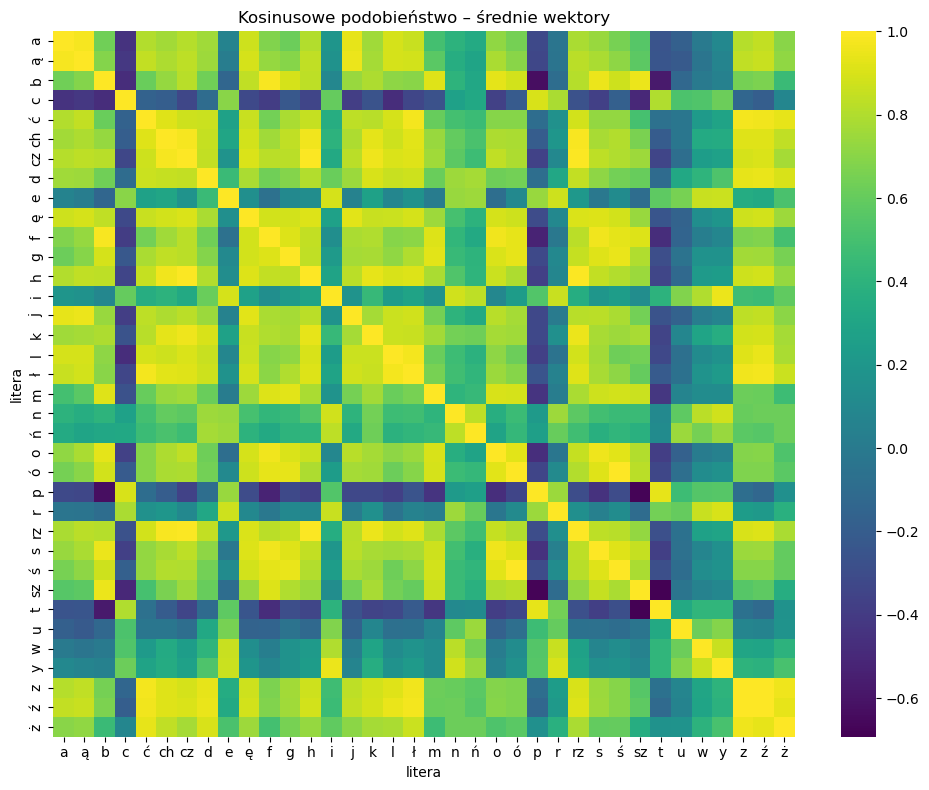

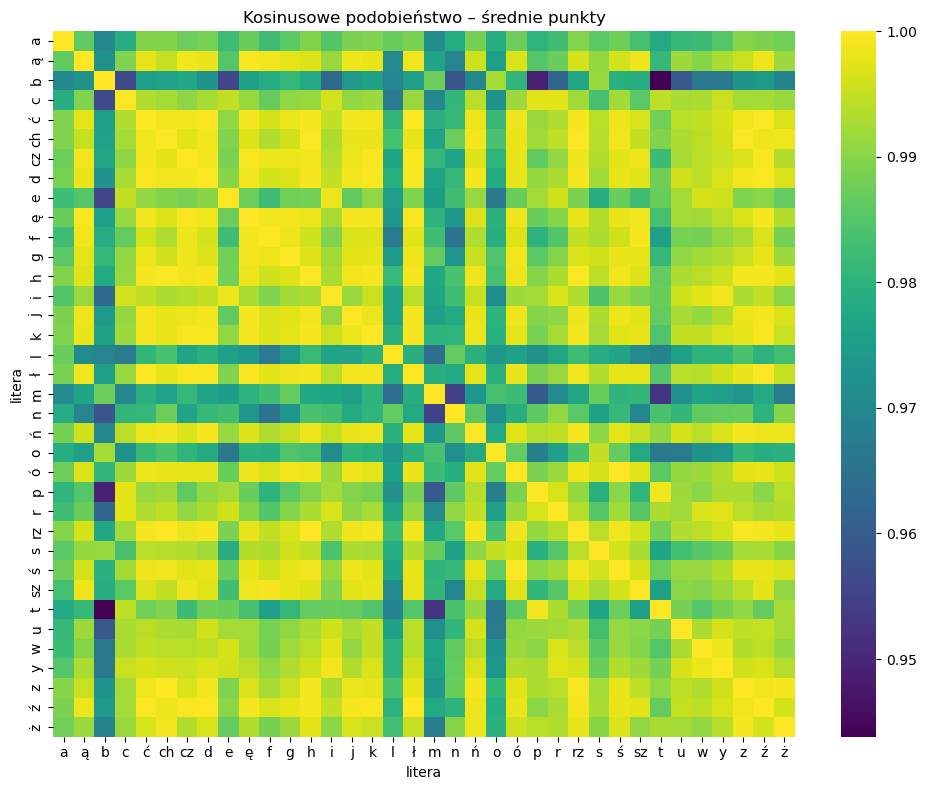

In [69]:
plt.figure(figsize=(10, 8))
sns.heatmap(vector_sim_df, cmap='viridis', annot=False)
plt.title("Kosinusowe podobieństwo – średnie wektory")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 8))
sns.heatmap(point_sim_df, cmap='viridis', annot=False)
plt.title("Kosinusowe podobieństwo – średnie punkty")
plt.tight_layout()
plt.show()

* Jasne pasy w poziomie i pionie oznaczają litery, które są podobne do wielu innych.
jasne linie → mogą być gestami o podobnym kierunku do innych znaków.

* Ciemne linie (niskie podobieństwo)
Litery, które mają wiele ciemniejszych miejsc – sugerują, że są dość unikalne w swoim układzie ruchu dłoni.

* Podobieństwa między literami z ogonkami/znakami diakrytycznymi
n i ń, o i ó, s i ś, z i ż/ź – zauważalnie mają jasne punkty względem siebie, co może sugerować, że gesty są podobne, a różnice subtelne.

Litery o podobnym kierunku gestu będzie można pogrupować, np przy hierarchii klas

## Ranking najbardziej i najmniej podobnych liter

In [6]:
print("\nNajbardziej podobne litery (na podstawie wektorów):\n")
for letter in vector_sim_df.index:
    similarities = vector_sim_df.loc[letter].drop(letter)
    top_similar = similarities.sort_values(ascending=False).head(3)
    print(f"Litera '{letter.upper()}':")
    for similar_letter, score in top_similar.items():
        print(f"  - {similar_letter.upper()} (similarity: {score:.3f})")
    print()

print("\nNajbardziej podobne litery (na podstawie punktów):\n")
for letter in point_sim_df.index:
    similarities = point_sim_df.loc[letter].drop(letter)
    top_similar = similarities.sort_values(ascending=False).head(3)
    print(f"Litera '{letter.upper()}':")
    for similar_letter, score in top_similar.items():
        print(f"  - {similar_letter.upper()} (similarity: {score:.3f})")
    print()

print("\nNajmniej podobne litery na podstawie wektorów:")
max_similarities = vector_sim_df.apply(lambda row: row.drop(row.name).max(), axis=1)
most_unique = max_similarities.sort_values()
for letter, score in most_unique.head(5).items():
    print(f"  - {letter.upper()} (najbliższe podobieństwo: {score:.3f})")

print("\nNajmniej podobne litery na podstawie punktów:")
max_similarities_points = point_sim_df.apply(lambda row: row.drop(row.name).max(), axis=1)
most_unique_points = max_similarities_points.sort_values()
for letter, score in most_unique_points.head(5).items():
    print(f"  - {letter.upper()} (najbliższe podobieństwo: {score:.3f})")



Najbardziej podobne litery (na podstawie wektorów):

Litera 'A':
  - Ą (similarity: 0.977)
  - J (similarity: 0.936)
  - L (similarity: 0.891)

Litera 'Ą':
  - A (similarity: 0.977)
  - J (similarity: 0.953)
  - Ę (similarity: 0.890)

Litera 'B':
  - F (similarity: 0.981)
  - SZ (similarity: 0.950)
  - S (similarity: 0.949)

Litera 'C':
  - P (similarity: 0.897)
  - T (similarity: 0.797)
  - R (similarity: 0.787)

Litera 'Ć':
  - Z (similarity: 0.971)
  - Ł (similarity: 0.967)
  - Ź (similarity: 0.964)

Litera 'CH':
  - RZ (similarity: 0.983)
  - CZ (similarity: 0.974)
  - H (similarity: 0.963)

Litera 'CZ':
  - RZ (similarity: 0.992)
  - H (similarity: 0.992)
  - CH (similarity: 0.974)

Litera 'D':
  - Ź (similarity: 0.941)
  - Z (similarity: 0.937)
  - Ż (similarity: 0.901)

Litera 'E':
  - I (similarity: 0.890)
  - R (similarity: 0.873)
  - Y (similarity: 0.863)

Litera 'Ę':
  - J (similarity: 0.924)
  - S (similarity: 0.913)
  - H (similarity: 0.908)

Litera 'F':
  - B (similarity

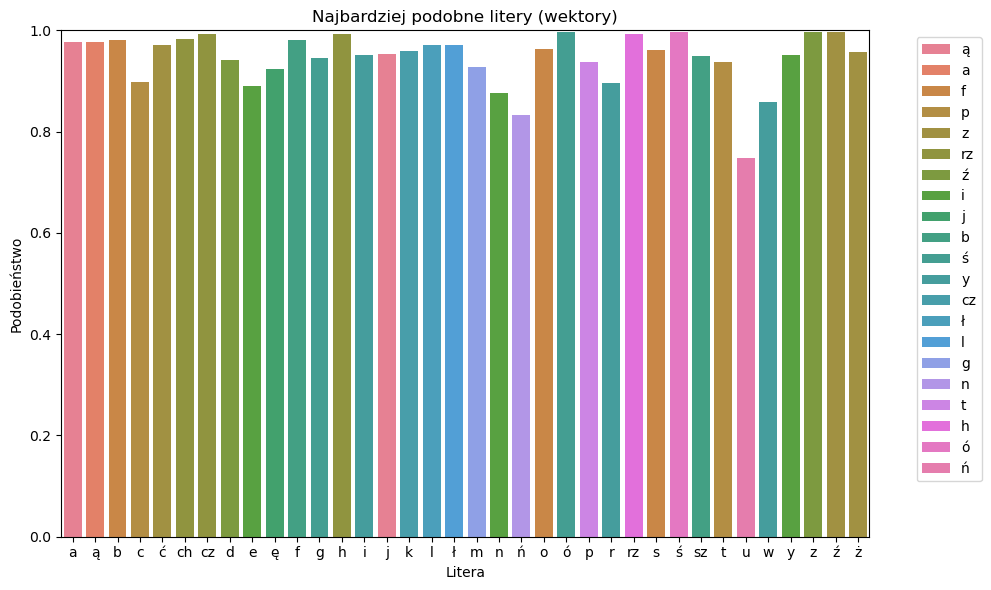

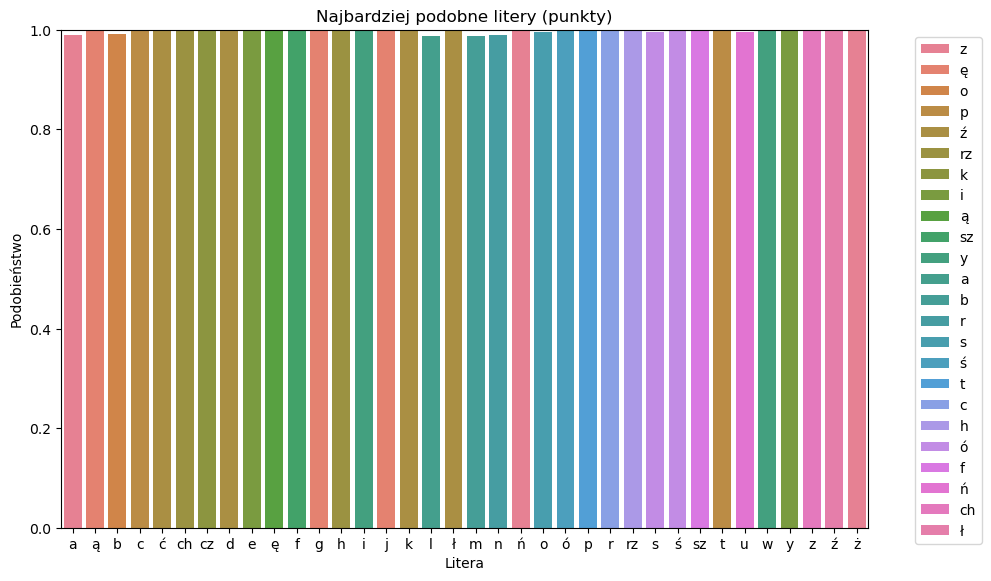

In [7]:
def plot_top_similar(sim_df, title):
    top_matches = {
        letter: sim_df.loc[letter].drop(letter).sort_values(ascending=False).head(1)
        for letter in sim_df.index
    }
    data = [(l, s.index[0], s.values[0]) for l, s in top_matches.items()]
    df = pd.DataFrame(data, columns=['Litera', 'Najbardziej podobna', 'Podobieństwo'])
    plt.figure(figsize=(10, 6))
    sns.barplot(data=df, x='Litera', y='Podobieństwo', hue='Najbardziej podobna')
    plt.title(title)
    plt.ylim(0, 1)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

plot_top_similar(vector_sim_df, "Najbardziej podobne litery (wektory)")
plot_top_similar(point_sim_df, "Najbardziej podobne litery (punkty)")


C:\Users\aleks\AppData\Local\Temp\ipykernel_29060\678397409.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=most_unique.index, y=most_unique.values, palette='viridis')


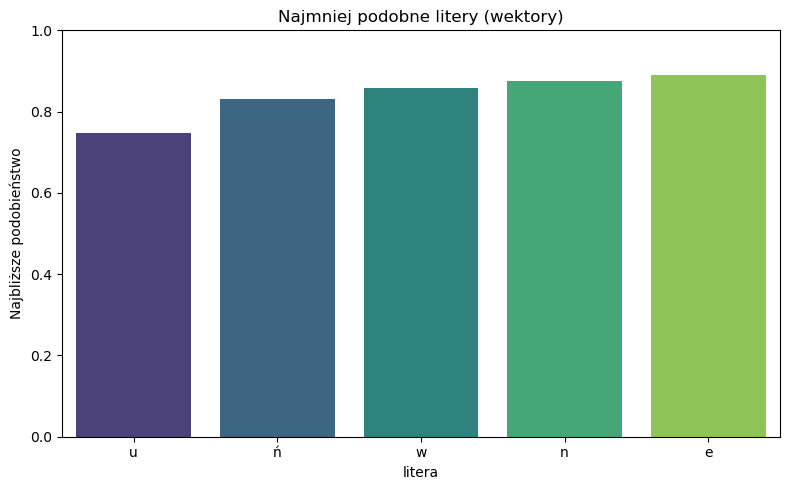

C:\Users\aleks\AppData\Local\Temp\ipykernel_29060\678397409.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=most_unique.index, y=most_unique.values, palette='viridis')


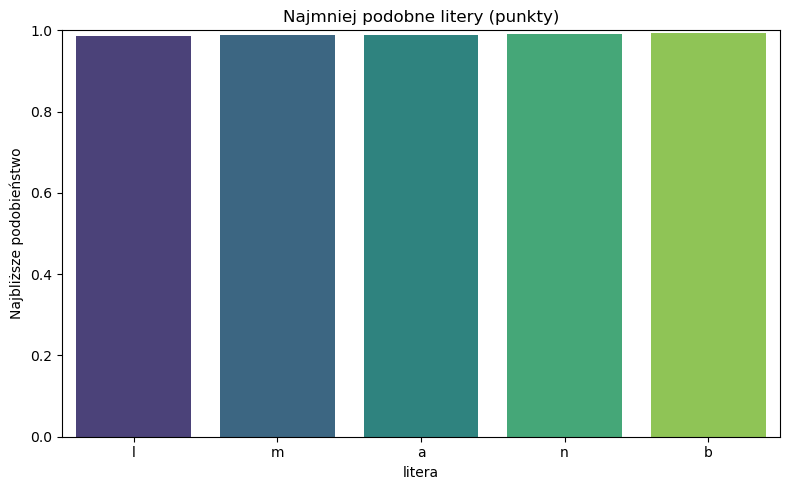

In [8]:

def plot_most_unique(sim_df, title):
    max_similarities = sim_df.apply(lambda row: row.drop(row.name).max(), axis=1)
    most_unique = max_similarities.sort_values().head(5)
    plt.figure(figsize=(8, 5))
    sns.barplot(x=most_unique.index, y=most_unique.values, palette='viridis')
    plt.title(title)
    plt.ylabel("Najbliższe podobieństwo")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()

plot_most_unique(vector_sim_df, "Najmniej podobne litery (wektory)")
plot_most_unique(point_sim_df, "Najmniej podobne litery (punkty)")


* Najbardziej podobne litery (na podstawie wektorów ruchu):
Litery: A, Ą, B, F, S, O, J – mają bardzo wysokie podobieństwa do innych (np. B ↔ F: 0.981, A ↔ Ą: 0.977).

Litery z diakrytykami (Ć, Ź, Ł) często silnie przypominają swoje wersje bazowe.

Ukazuje to powtarzalność i ogólność niektórych ruchów – potencjalne źródło błędów klasyfikacji.

* Najmniej podobne litery (wektory):
U (0.748), Ń, W, N, E – mają najmniejsze podobieństwa → potencjalnie najbardziej charakterystyczne i łatwiejsze do odróżnienia.

Ruch tych liter wyraźnie odbiega od reszty (unikalna trajektoria, kierunek lub tempo).

* Na podstawie punktów (pozycja dłoni):
Większość liter jest bardzo podobna – często >0.99 (np. CH ↔ RZ ↔ Z: 1.000).

Różnice między literami są często subtelne – np. Ć ↔ Ź ↔ Ł: 1.000.

* Wnioski:
Ruch dłoni (wektory) dostarcza więcej różnic niż same pozycje palców – kluczowy do rozróżniania znaków.

Litery CH, CZ, RZ, H – niemal identyczne → mogą być najtrudniejsze do rozróżnienia przez klasyfikator.

Łączenie cech dynamicznych i statycznych (punktów i wektorów) zwiększa skuteczność rozpoznawania.



## Analiza długości wektorów

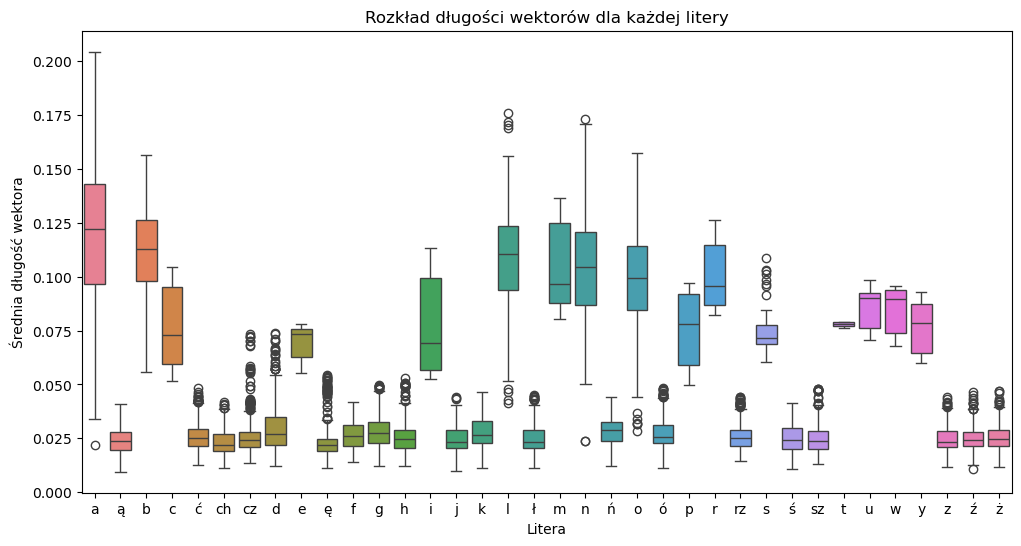

In [9]:
plt.figure(figsize=(12, 6))
vector_lengths = {l: [np.linalg.norm(v.reshape(-1, 3), axis=1).mean() for v in vs] for l, vs in all_vectors_dict.items()}
sns.boxplot(data=pd.DataFrame.from_dict(vector_lengths, orient='index').T)
plt.title("Rozkład długości wektorów dla każdej litery")
plt.ylabel("Średnia długość wektora")
plt.xlabel("Litera")
plt.show()

Długość wektora może odzwierciedlać:

Złożoność ruchu: Im dłuższy wektor, tym bardziej skomplikowany lub obszerny gest (np. wymagający większej przestrzeni lub precyzji).

Zmienność wykonania: Długie wektory mogą wskazywać na większą różnorodność w sposobie migania tych liter przez różnych użytkowników.

Litera "a":
Długi wektor i wysokie podobieństwo kosinusowe (wcześniej) → sugeruje, że może być często mylona z innymi, mimo złożoności.

Litera "l":
Długi wektor i niskie podobieństwo kosinusowe → unikalna, ale trudna do stabilnego wykonania.

## Rozkład kątów między wektorami

C:\Users\aleks\AppData\Local\Temp\ipykernel_29060\2467419038.py:4: RuntimeWarning: invalid value encountered in scalar divide
  cos_theta = np.dot(v1, v2) / (norm(v1) * norm(v2))


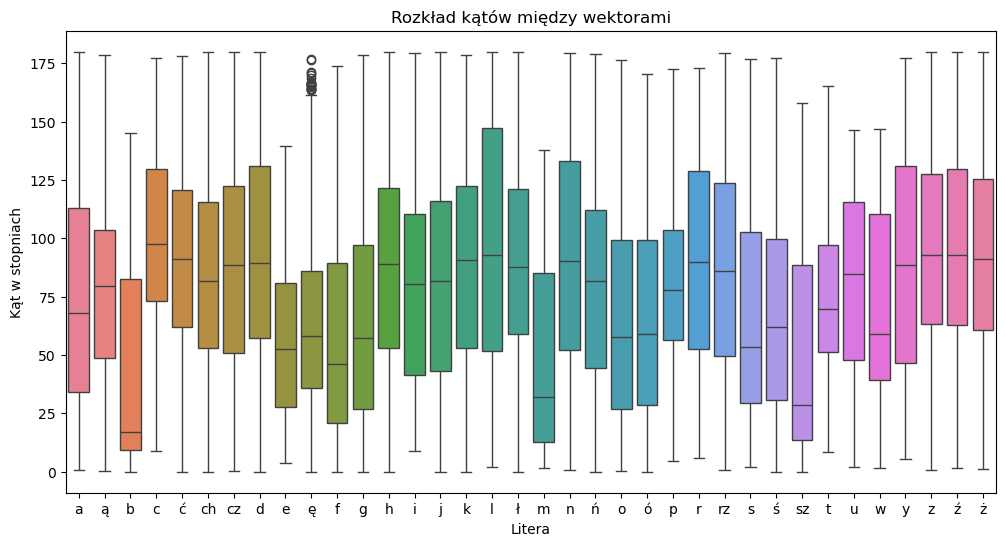

In [10]:
from numpy.linalg import norm

def angle_between(v1, v2):
    cos_theta = np.dot(v1, v2) / (norm(v1) * norm(v2))
    return np.arccos(np.clip(cos_theta, -1.0, 1.0))

angle_dict = defaultdict(list)
for letter, vectors_list in all_vectors_dict.items():
    for v in vectors_list:
        reshaped = v.reshape(-1, 3)
        for i in range(len(reshaped) - 1):
            angle = angle_between(reshaped[i], reshaped[i+1])
            angle_dict[letter].append(np.degrees(angle))

plt.figure(figsize=(12, 6))
sns.boxplot(data=pd.DataFrame.from_dict(angle_dict, orient='index').T)
plt.title("Rozkład kątów między wektorami")
plt.ylabel("Kąt w stopniach")
plt.xlabel("Litera")
plt.show()

* Litery o małej zmienności kątów (wąskie boxploty, np. a, e, o):

Ich gesty są płynne i przewidywalne (np. ruch okrężny dla "o" lub stała pozycja dla "a").

Niska zmienność ułatwia rozpoznanie, ale może prowadzić do pomyłek między podobnymi literami (np. "a" vs. "e").

* Litery o dużej zmienności kątów (szerokie boxploty, np. ż, sz, m):

Wymagają złożonych, nieciągłych ruchów (np. drgania dla "ż" lub zmiany płaszczyzn dla "m").

Są trudniejsze do klasyfikacji, ale dzięki unikalnym sekwencjom kątów mogą być lepiej odróżnialne.

Gesty z "zawracaniem" (np. litera "z" może wymagać ruchu tam i z powrotem).


## Odchylenie standardowe punktów

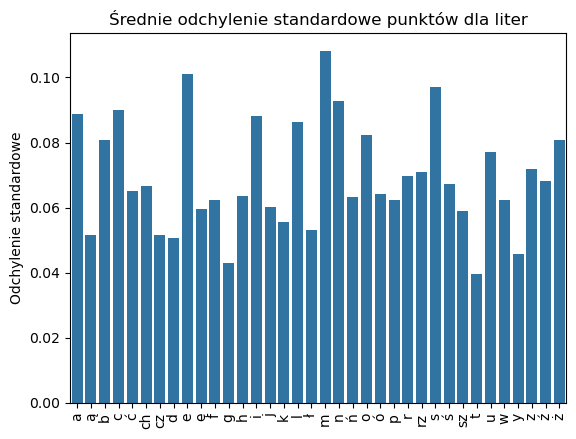

In [ ]:
std_points = {l: np.std(np.stack(p), axis=0).mean() for l, p in all_points_dict.items()}
sns.barplot(x=list(std_points.keys()), y=list(std_points.values()))
plt.title("Średnie odchylenie standardowe punktów dla liter")
plt.ylabel("Odchylenie standardowe")
plt.xticks(rotation=90)
plt.show()

Dobrze będzie testować na parach liter o podobnym odchyleniu (np. m vs. n).
Można połączyć odchylenie standardowe z długością wektorów i kątami dla lepszej dokładności.
Zwiększyć liczbę próbek dla liter z odchyleniem >0.06.

Proste litery: Niskie odchylenie → łatwe do rozpoznania, ale wymagają precyzyjnego odróżnienia.
Złożone litery: Wysokie odchylenie → trudne, ale oferują unikalne cechy do identyfikacji.

## Korelacje między wspórzędnymi punktów

c:\Users\aleks\anaconda3\envs\psio\Lib\site-packages\numpy\lib\function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\aleks\anaconda3\envs\psio\Lib\site-packages\numpy\lib\function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


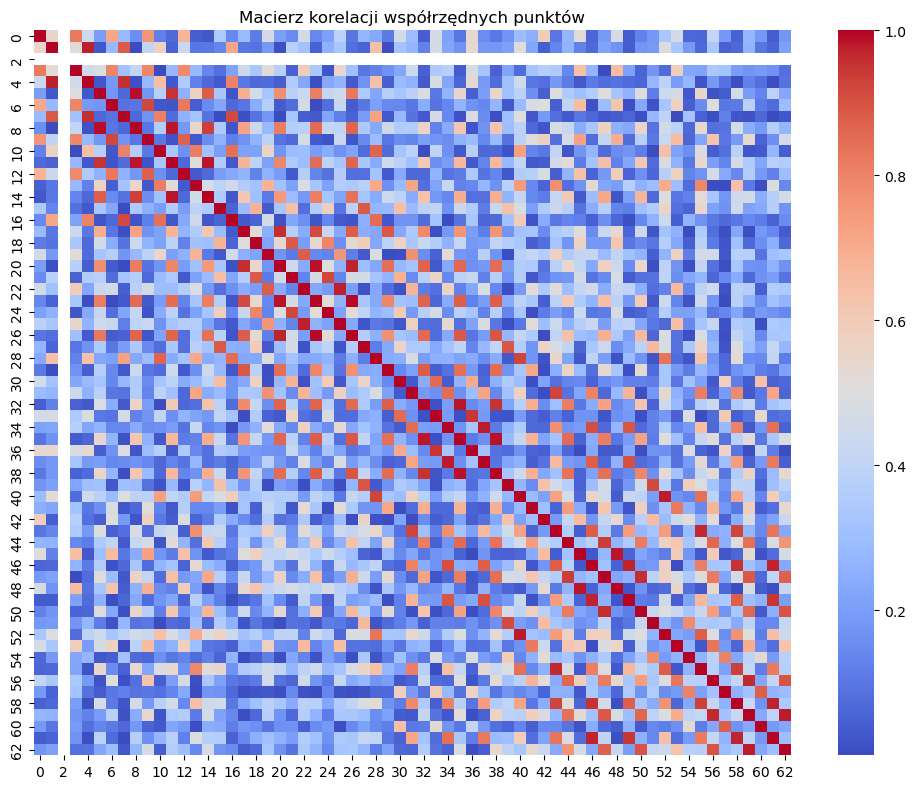

In [43]:
# Upewnij się, że masz prawidłowo zdefiniowane mean_points_df przed tym kodem
corr_df = pd.DataFrame(np.corrcoef(mean_points_df.T)).abs()

# Tworzenie wykresu z macierzą korelacji
plt.figure(figsize=(10, 8))  # Dodanie figsize

sns.heatmap(corr_df, cmap='coolwarm', annot=False, fmt=".1f")  # Dodanie adnotacji na macierzy
plt.title("Macierz korelacji współrzędnych punktów")
plt.tight_layout()
plt.show()

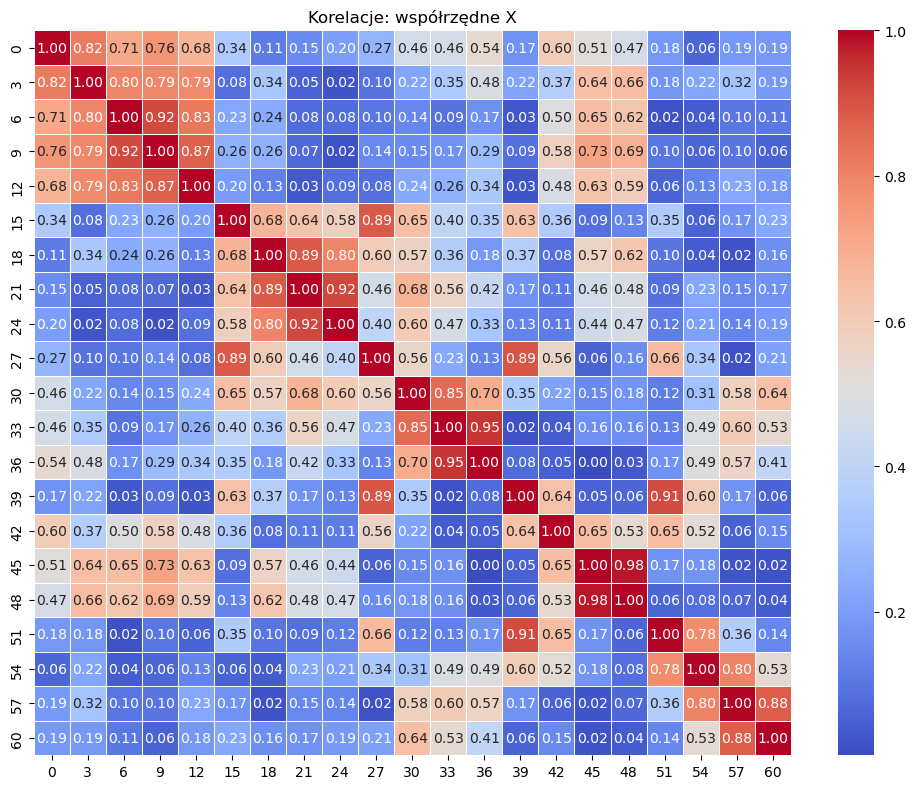

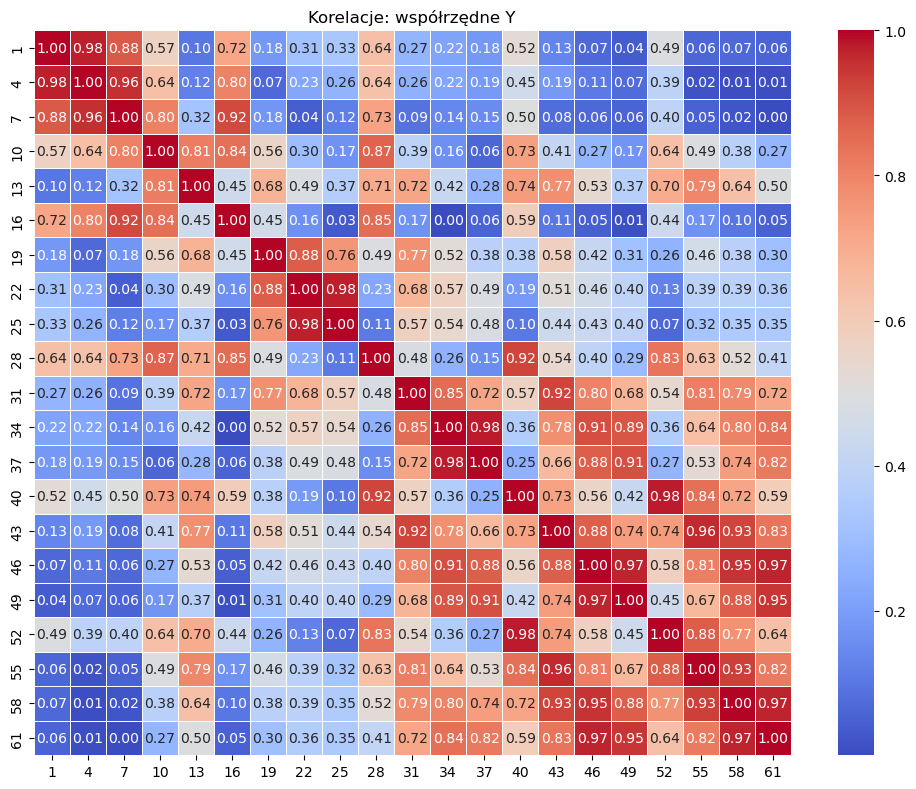

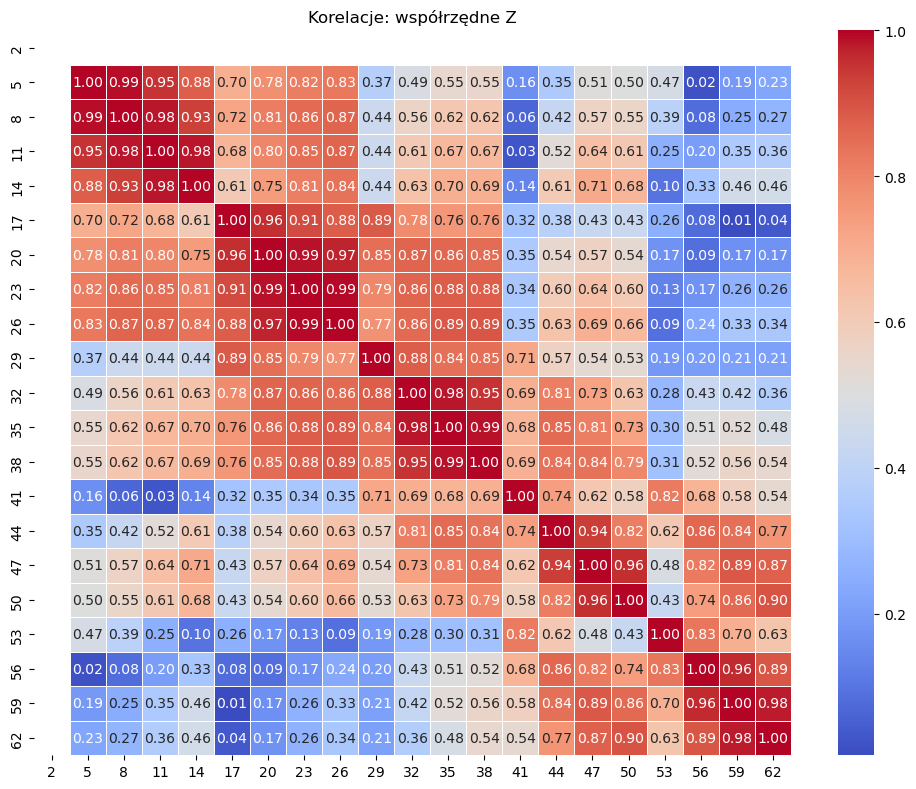

In [13]:
# Zakładamy, że mean_points_df to DataFrame z 63 kolumnami: P0x, P0y, P0z, ..., P20x, P20y, P20z
x_cols = mean_points_df.columns[::3]
y_cols = mean_points_df.columns[1::3]
z_cols = mean_points_df.columns[2::3]

def plot_corr_heatmap(columns, title):
    corr_part = mean_points_df[columns].corr().abs()
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr_part, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
    plt.title(title)
    plt.tight_layout()
    plt.show()

plot_corr_heatmap(x_cols, "Korelacje: współrzędne X")
plot_corr_heatmap(y_cols, "Korelacje: współrzędne Y")
plot_corr_heatmap(z_cols, "Korelacje: współrzędne Z")


## Długość trajektorii punktów

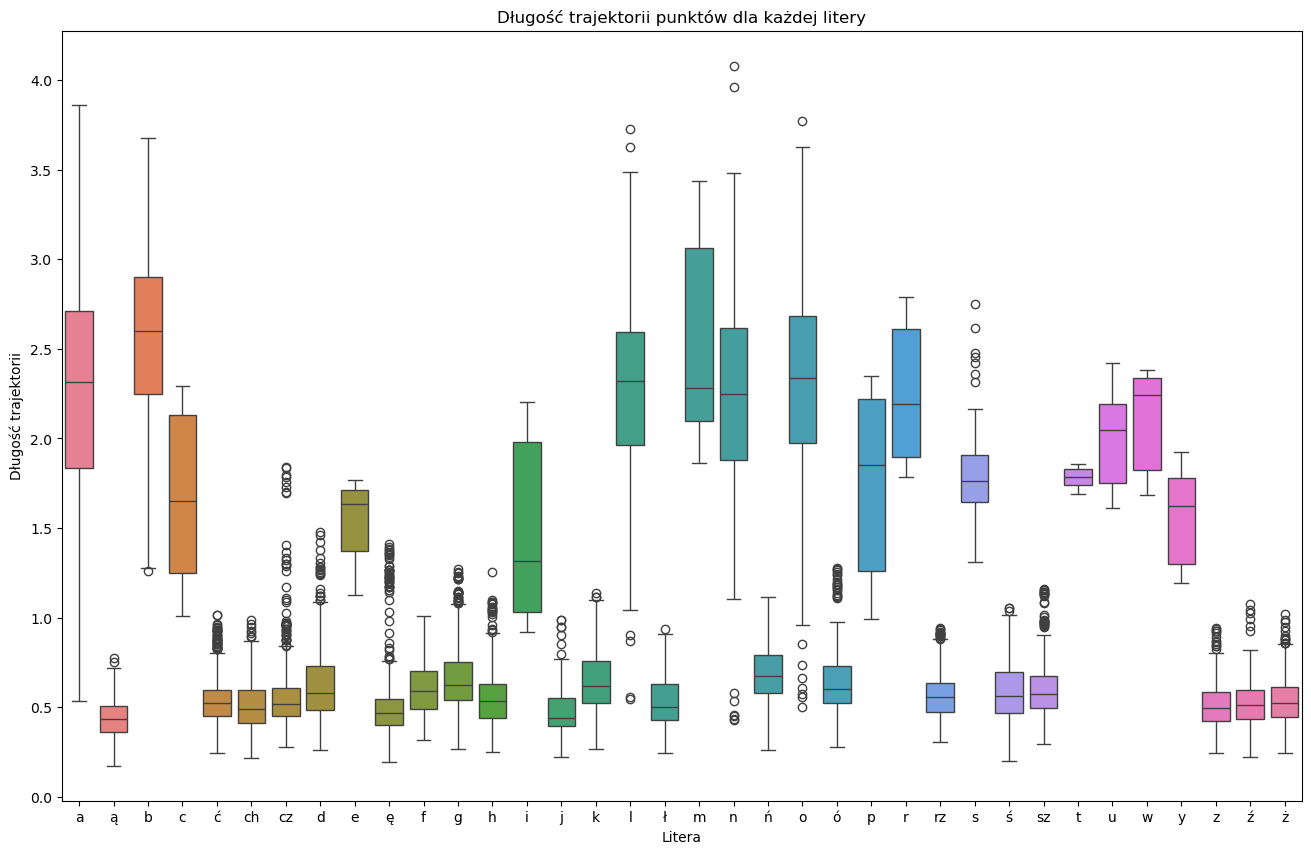

In [48]:
traj_lengths = {l: [np.sum(np.linalg.norm(np.diff(p.reshape(-1, 3), axis=0), axis=1)) for p in ps] for l, ps in all_points_dict.items()}
plt.figure(figsize=(16, 10)) 
sns.boxplot(data=pd.DataFrame.from_dict(traj_lengths, orient='index').T)
plt.title("Długość trajektorii punktów dla każdej litery")
plt.ylabel("Długość trajektorii")
plt.xlabel("Litera")
plt.show()

## PCA dla wektorów po filtracji

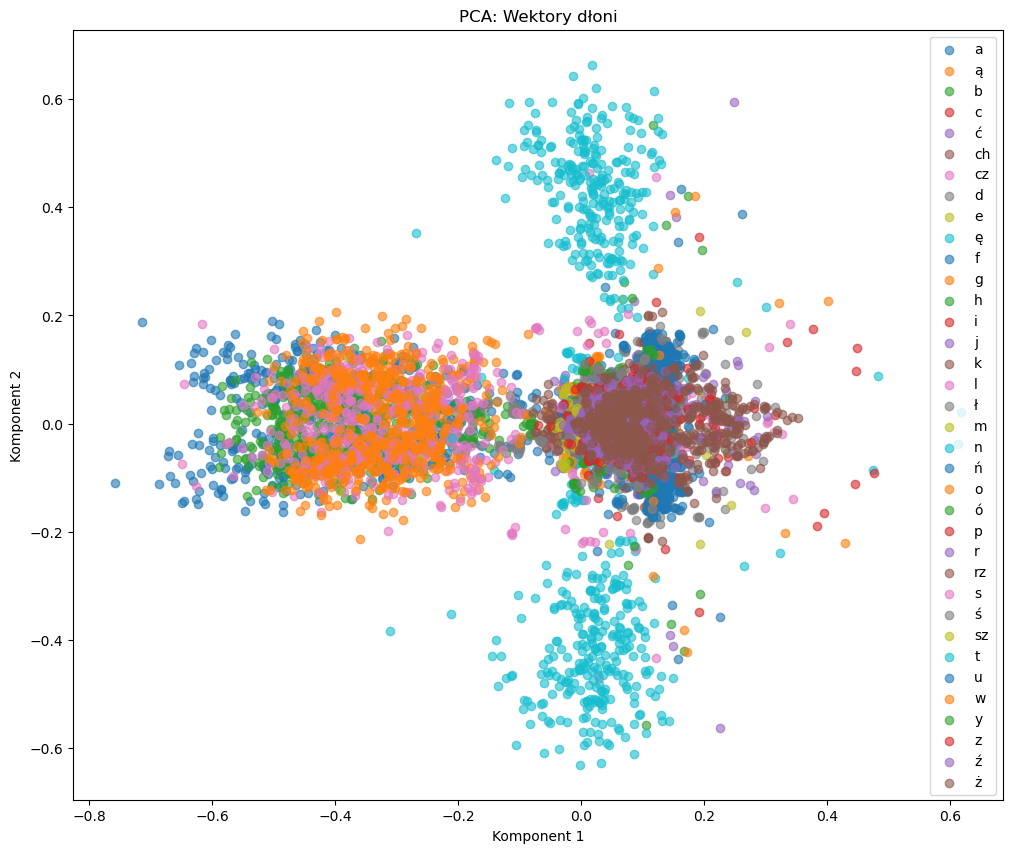

In [50]:
from sklearn.decomposition import PCA

# Łączymy wszystkie wektory z różnych liter
all_vectors_flat = np.array([v for vectors in all_vectors_dict.values() for v in vectors])

# PCA - redukcja do 2 wymiarów
pca = PCA(n_components=2)
pca_vectors = pca.fit_transform(all_vectors_flat)

# Dodajemy PCA zredukowane do 2D do słownika liter
pca_dict = {}
start_idx = 0
for letter, vectors in all_vectors_dict.items():
    num_vectors = len(vectors)
    pca_dict[letter] = pca_vectors[start_idx:start_idx + num_vectors]
    start_idx += num_vectors

# Wizualizacja PCA
plt.figure(figsize=(12, 10))
for letter, pca_data in pca_dict.items():
    plt.scatter(pca_data[:, 0], pca_data[:, 1], label=letter, alpha=0.6)
plt.title('PCA: Wektory dłoni')
plt.xlabel('Komponent 1')
plt.ylabel('Komponent 2')
plt.legend()
plt.show()


Wyraźne skupiska:
Niektóre litery (np. t, b, a) tworzą gęste skupiska, co może oznaczać, że mają unikalne cechy odróżniające je od innych.

Nakładanie się klas:
Wiele liter pokrywa się w przestrzeni PCA, np. l, m, n, o, p, r itd., co sugeruje, że są do siebie podobne pod względem reprezentacji wektorowej dłoni — być może mają zbliżone gesty lub cechy.

Rozproszenie klas:
Litera t jest silnie rozproszona i oddalona od innych, co może świadczyć o bardzo charakterystycznym wektorze dłoni lub dużej zmienności tej litery.

Możliwe problemy klasyfikacyjne:
Z powodu znacznego nakładania się punktów (czyli reprezentacji liter), klasyfikator może mieć trudności z dokładnym rozróżnieniem niektórych znaków.

## PCA dla punktów

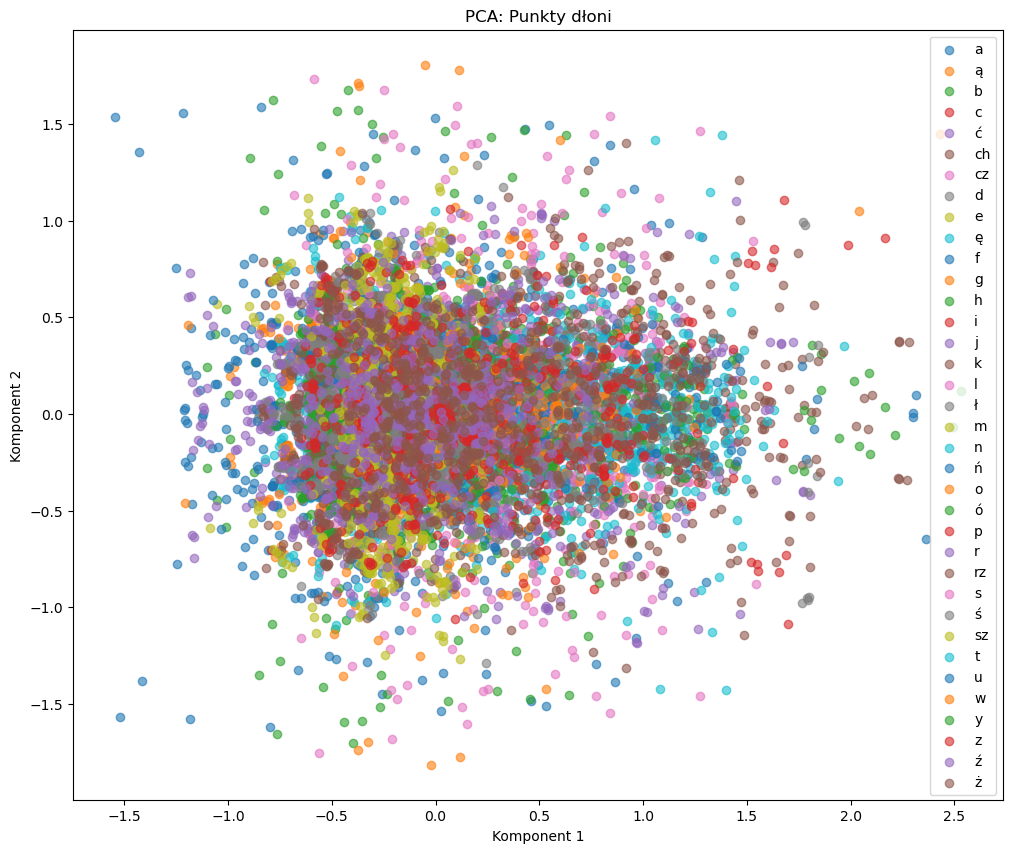

In [51]:
# Łączymy wszystkie punkty z różnych liter
all_points_flat = np.array([p for points in all_points_dict.values() for p in points])

# PCA - redukcja do 2 wymiarów
pca_points = pca.fit_transform(all_points_flat)

# Dodajemy PCA zredukowane do 2D do słownika liter
pca_points_dict = {}
start_idx = 0
for letter, points in all_points_dict.items():
    num_points = len(points)
    pca_points_dict[letter] = pca_points[start_idx:start_idx + num_points]
    start_idx += num_points

# Wizualizacja PCA dla punktów
plt.figure(figsize=(12, 10))
for letter, pca_data in pca_points_dict.items():
    plt.scatter(pca_data[:, 0], pca_data[:, 1], label=letter, alpha=0.6)
plt.title('PCA: Punkty dłoni')
plt.xlabel('Komponent 1')
plt.ylabel('Komponent 2')
plt.legend()
plt.show()


## Kmeans na PCA 

Kod realizuje klasteryzację liter na podstawie ich cech z wykorzystaniem algorytmu KMeans oraz redukcję wymiarów za pomocą PCA w celu wizualizacji wyników. Celem jest pokazanie, jak litery grupują się ze sobą w przestrzeni cech, a także jak algorytm KMeans dzieli je na 4 różne grupy

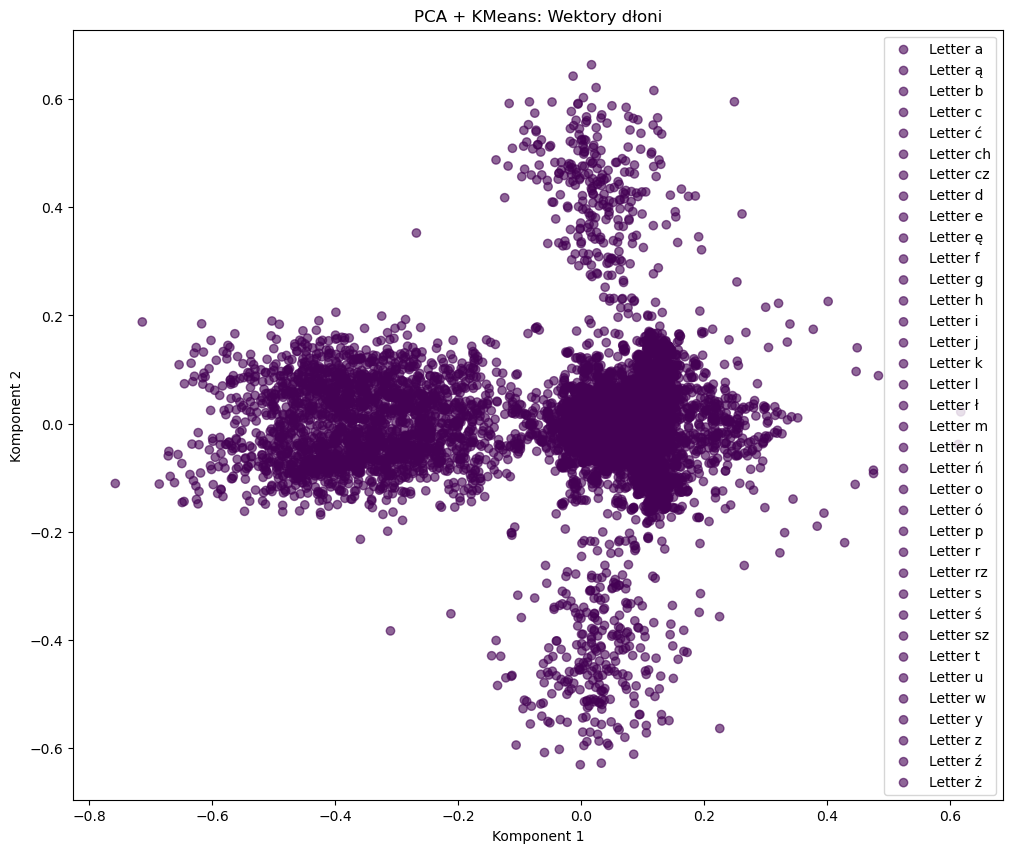

In [115]:
from sklearn.cluster import KMeans


kmeans = KMeans(n_clusters=4, random_state=42)
kmeans_labels = kmeans.fit_predict(pca_vectors)

# Wizualizacja z KMeans
plt.figure(figsize=(12, 10))
for i, letter in enumerate(all_vectors_dict.keys()):
    letter_data = pca_dict[letter]
    plt.scatter(letter_data[:, 0], letter_data[:, 1], label=f'Letter {letter}', c=[kmeans_labels[i]]*len(letter_data), cmap='viridis', alpha=0.6)

plt.title('PCA + KMeans: Wektory dłoni')
plt.xlabel('Komponent 1')
plt.ylabel('Komponent 2')
plt.legend()
plt.show()


## Violinplot dla dlugosci wektorow

Kod tworzy wykres violinplot, który ilustruje rozproszenie i rozkład długości wektorów dla różnych liter. Violinplot pozwala na lepsze zrozumienie, jak różne litery są reprezentowane przez swoje wektory, w tym ich zróżnicowanie, rozkład i ewentualne anomalie.

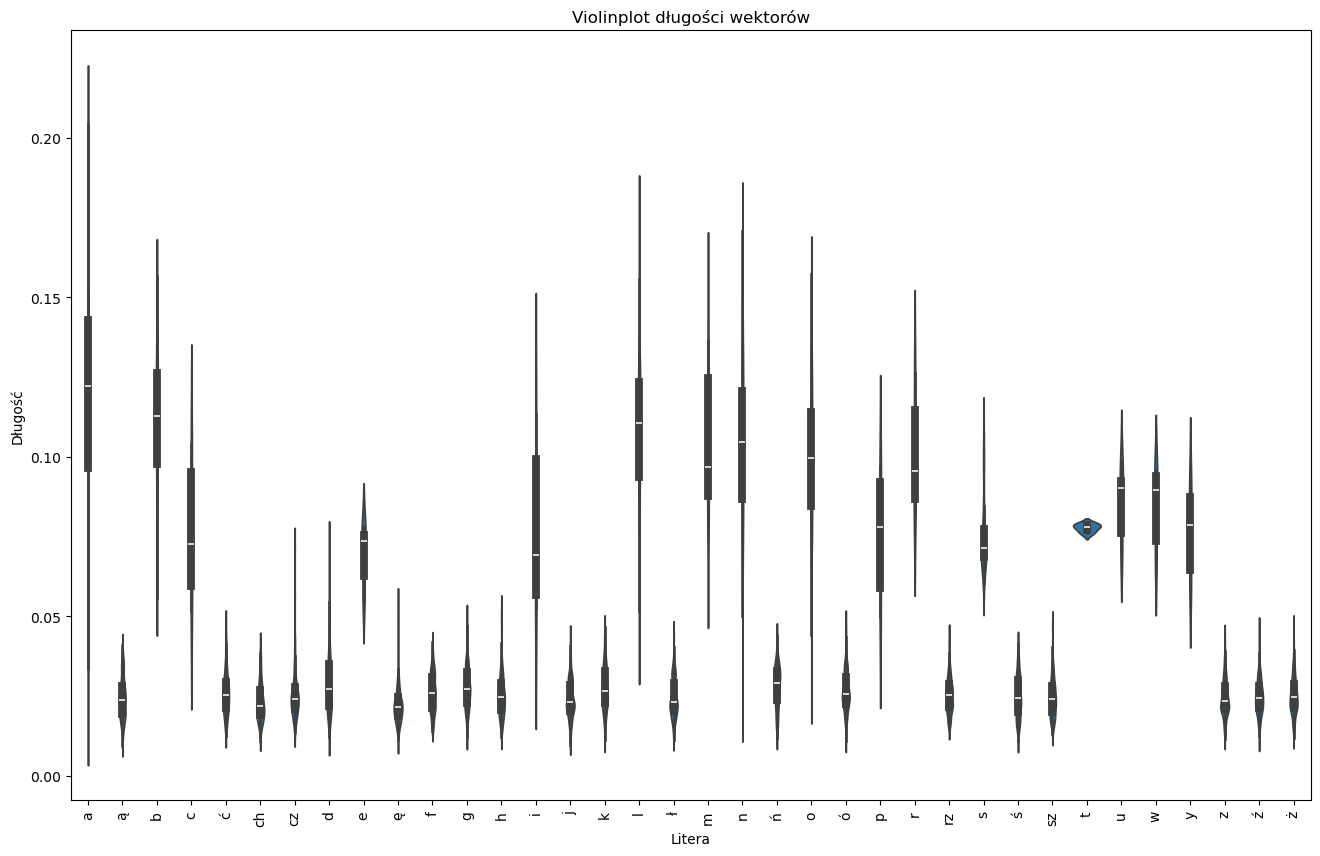

In [58]:
violin_data = pd.DataFrame.from_dict(vector_lengths, orient='index').T.melt(var_name='Litera', value_name='Długość')
plt.figure(figsize=(16, 10)) 
sns.violinplot(data=violin_data, x='Litera', y='Długość')
plt.title("Violinplot długości wektorów")
plt.xticks(rotation=90)
plt.show()

## Odległości euklidesowe

Robienie tego typu analizy za pomocą macierzy odległości euklidesowych i jej wizualizacji pozwala na:

Zrozumienie podobieństw i różnic między obiektami w przestrzeni cech,

Identyfikację grup i klastrów podobnych obiektów,

Weryfikację poprawności reprezentacji obiektów w przestrzeni cech.

W kontekście liter, takie podejście może pomóc w zrozumieniu, które litery są do siebie podobne pod względem ich kształtu

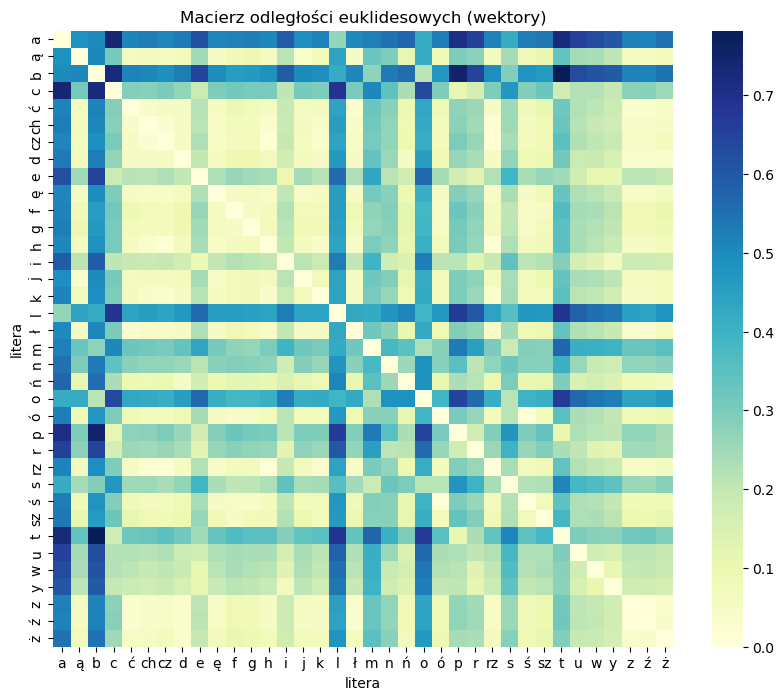

In [59]:
from sklearn.metrics.pairwise import euclidean_distances

eucl_df = pd.DataFrame(euclidean_distances(mean_vectors_df), index=mean_vectors_df.index, columns=mean_vectors_df.index)
plt.figure(figsize=(10, 8)) 
sns.heatmap(eucl_df, cmap='YlGnBu')
plt.title("Macierz odległości euklidesowych (wektory)")
plt.show()

## t-SNE z różnymi perlexities

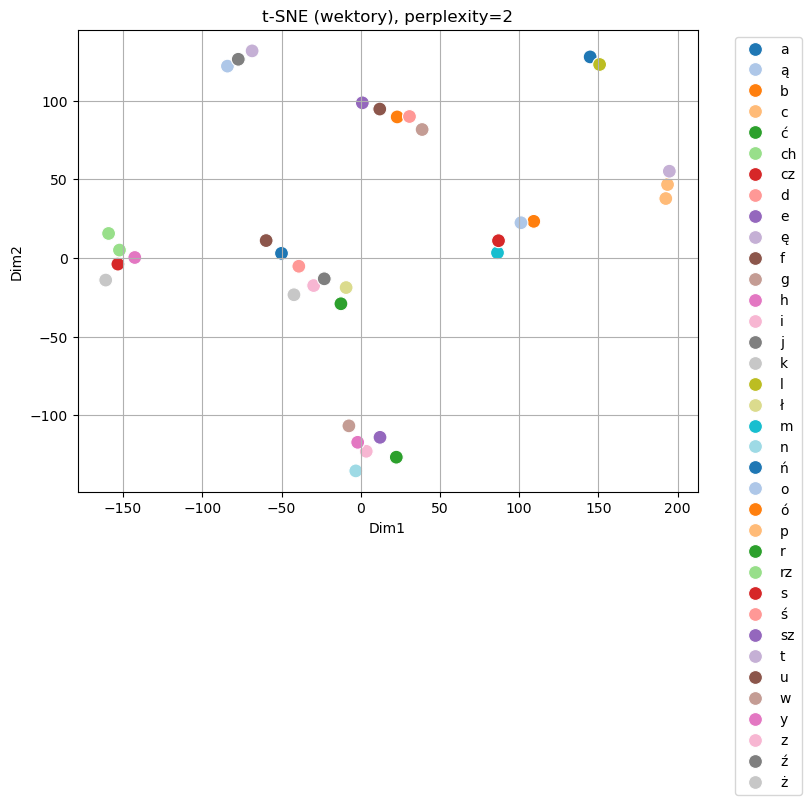

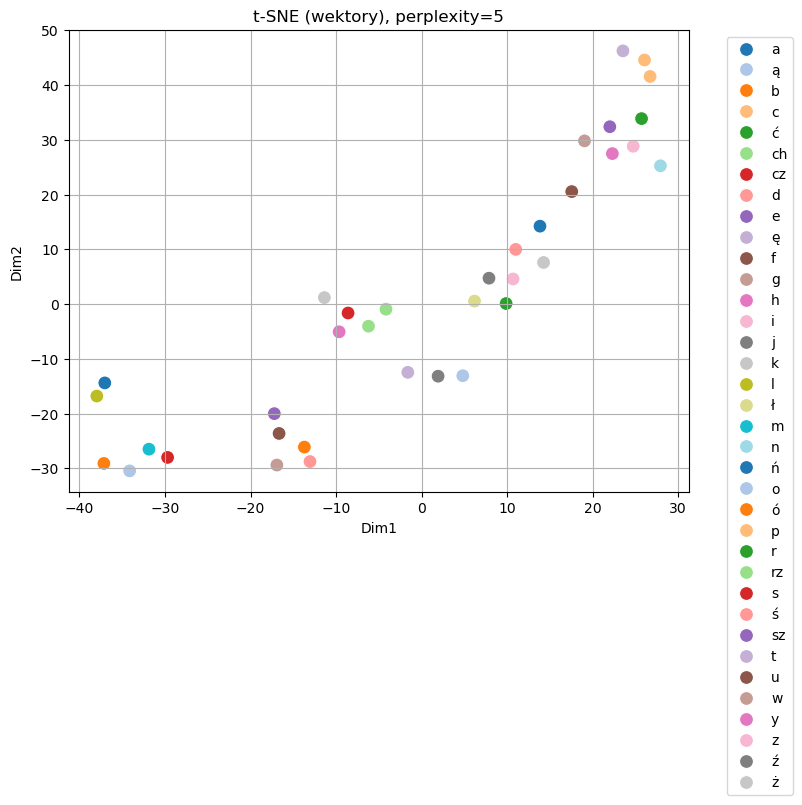

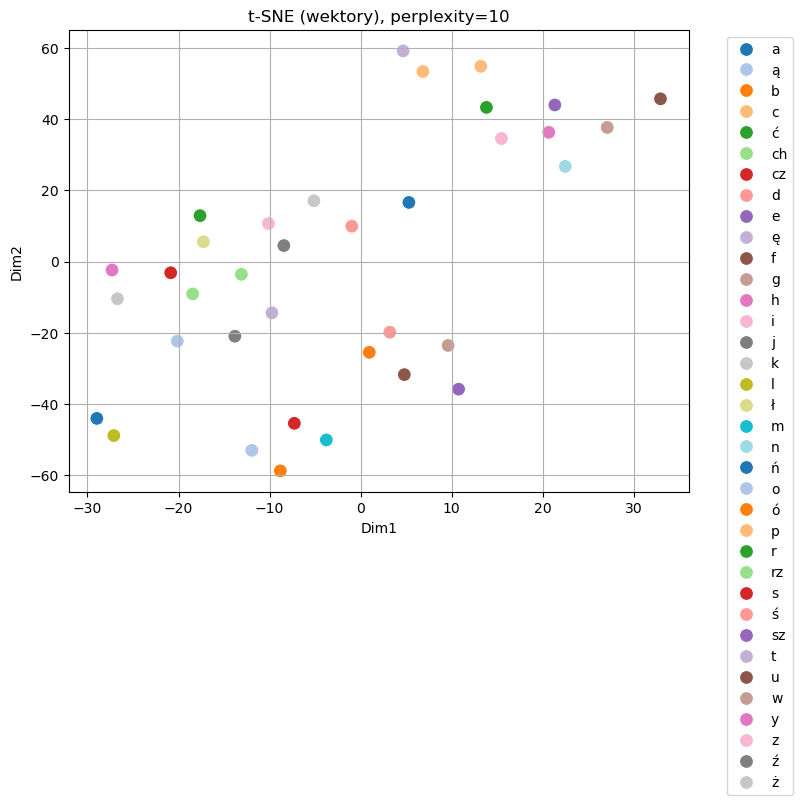

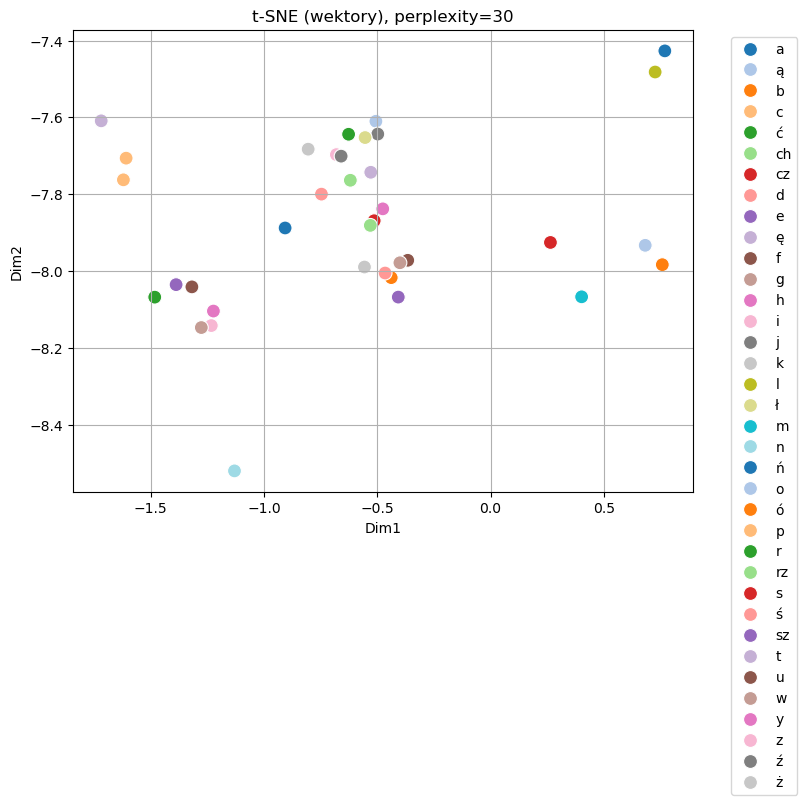

In [20]:
for p in [2, 5, 10, 30]:
    tsne = TSNE(n_components=2, perplexity=p, random_state=42)
    tsne_result = tsne.fit_transform(mean_vectors_df)
    df_tsne = pd.DataFrame(tsne_result, columns=['Dim1', 'Dim2'])
    df_tsne['label'] = mean_vectors_df.index
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=df_tsne, x='Dim1', y='Dim2', hue='label', palette='tab20', s=100)
    plt.title(f"t-SNE (wektory), perplexity={p}")
    plt.grid(True)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.show()

## Uśredniony kształt dłoni

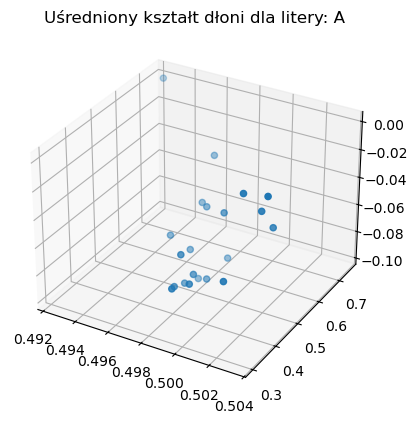

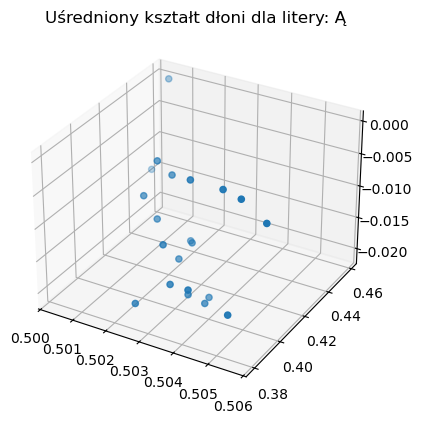

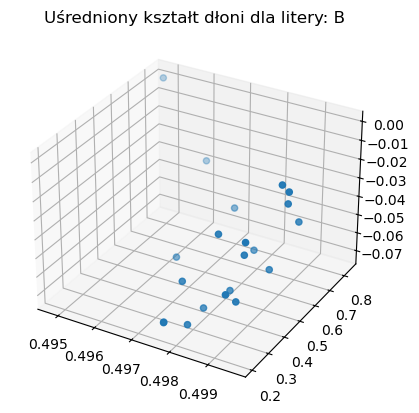

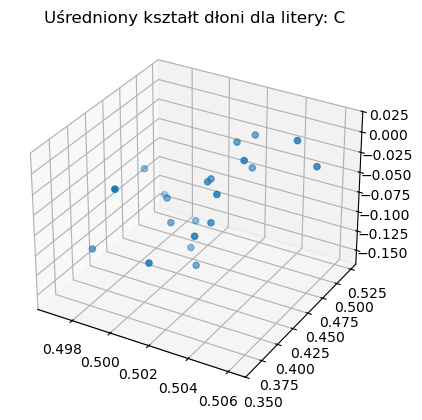

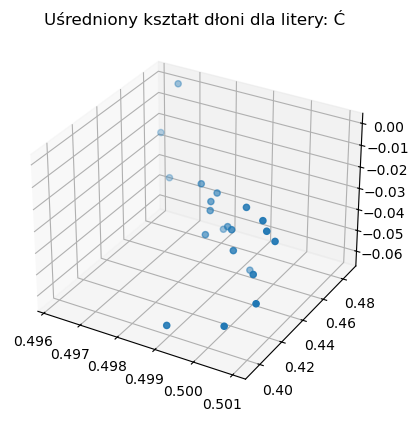

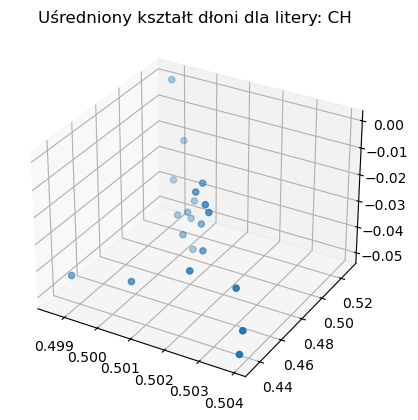

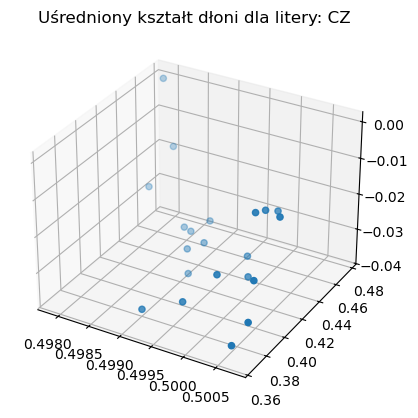

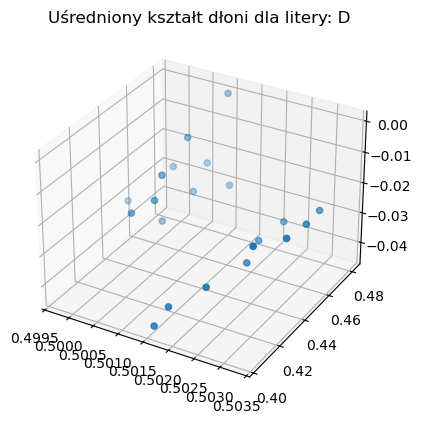

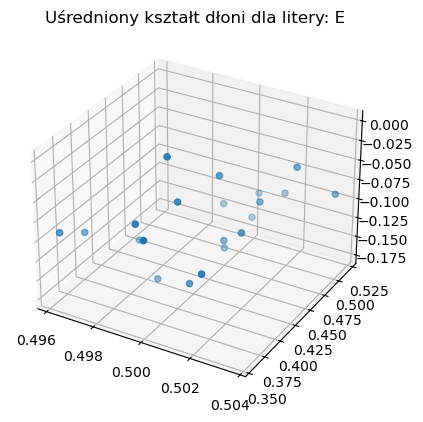

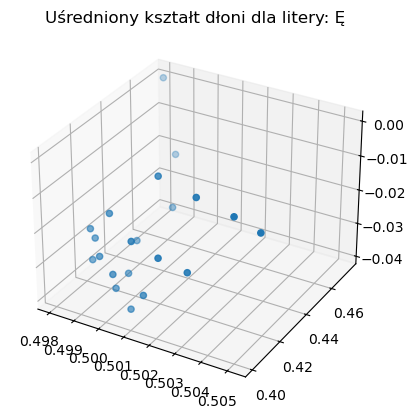

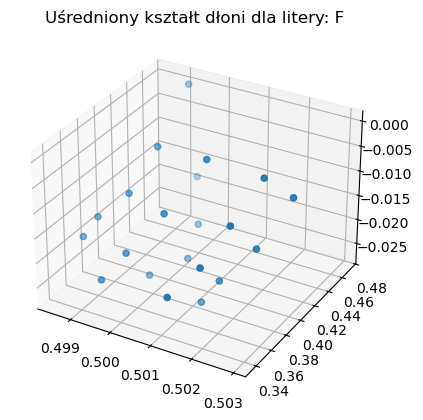

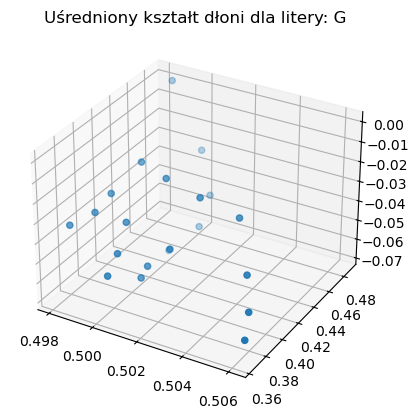

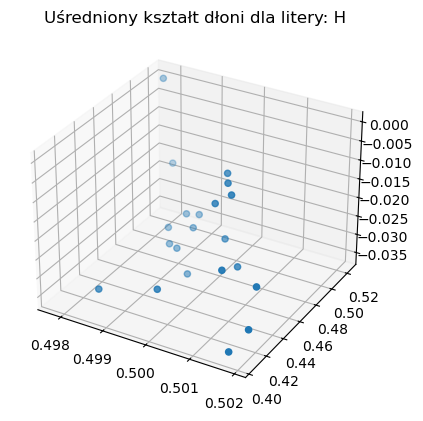

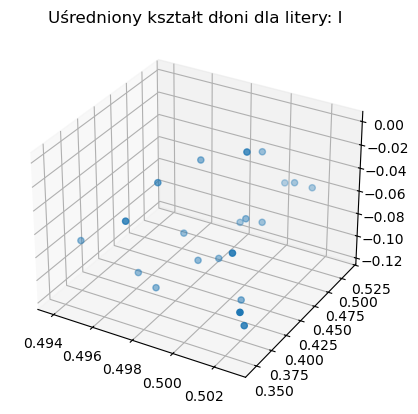

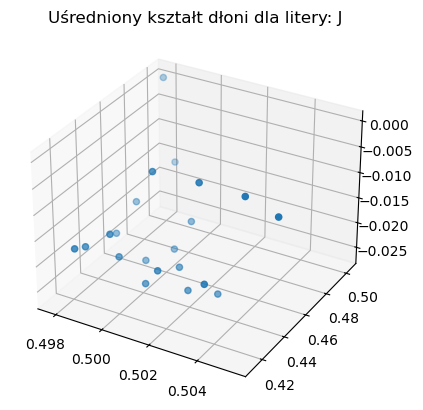

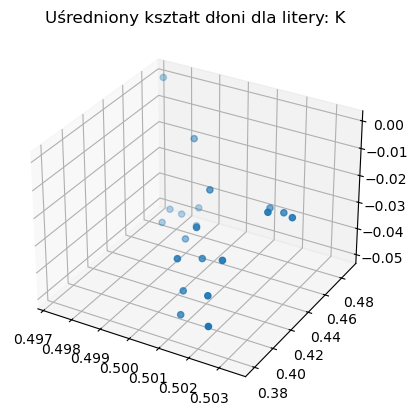

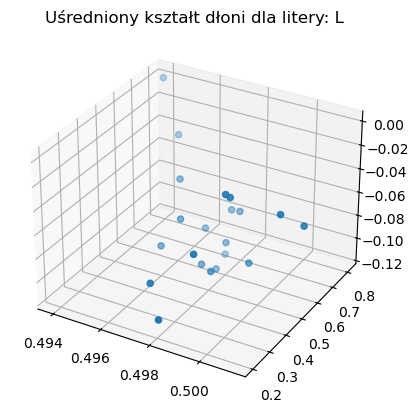

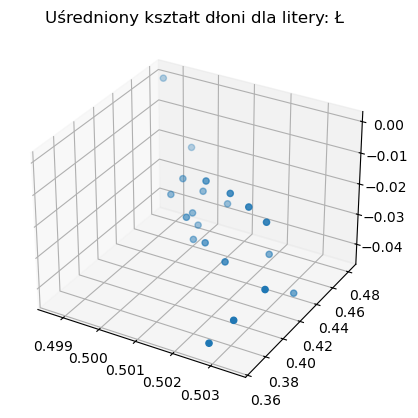

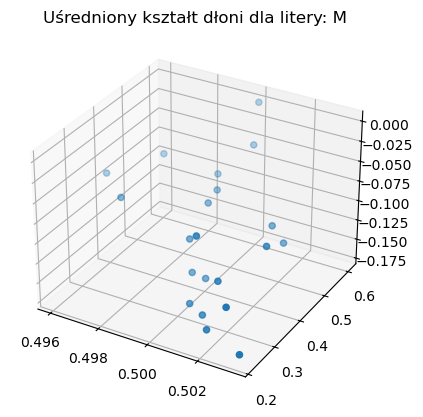

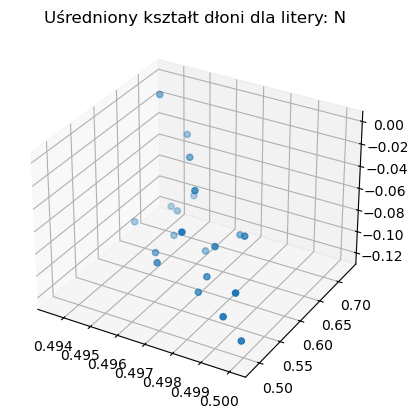

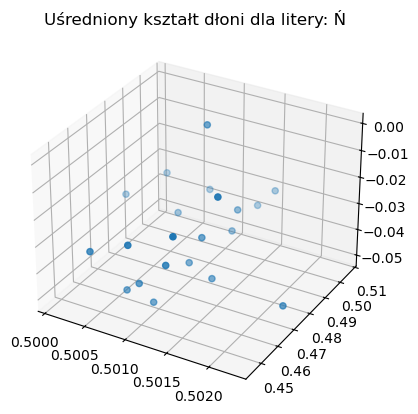

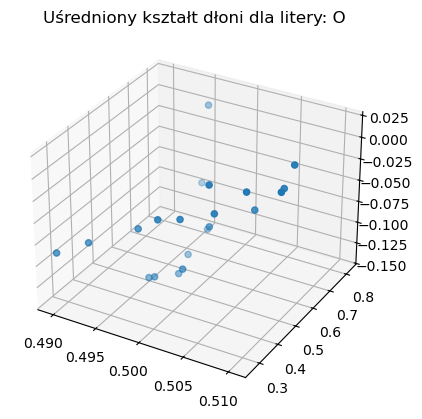

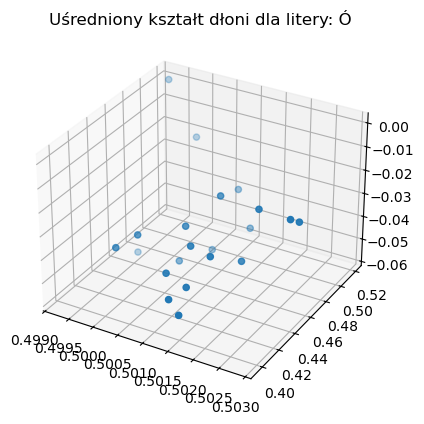

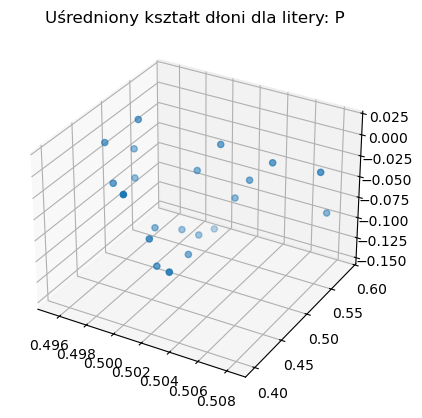

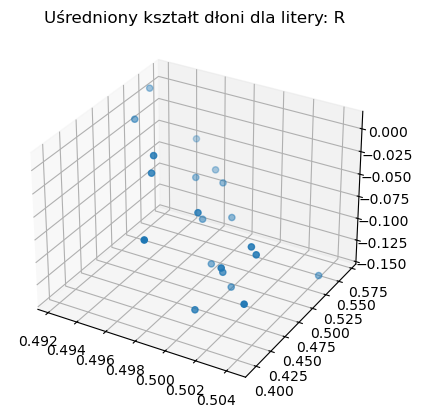

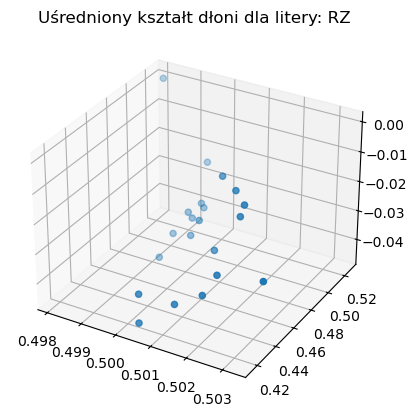

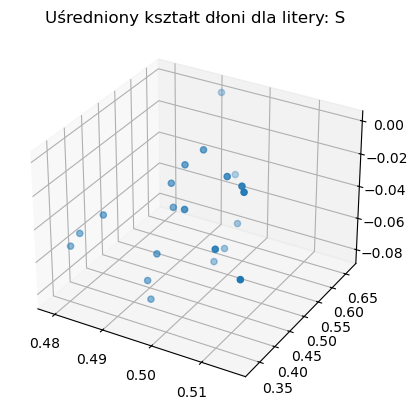

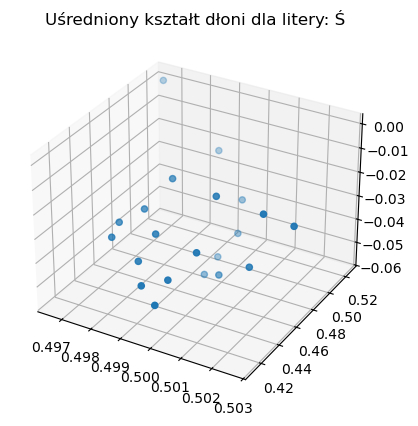

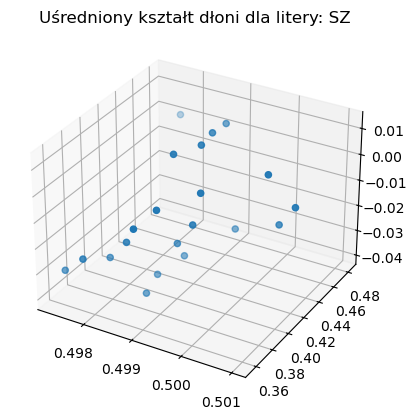

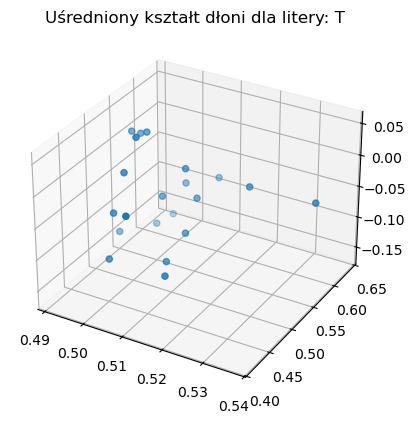

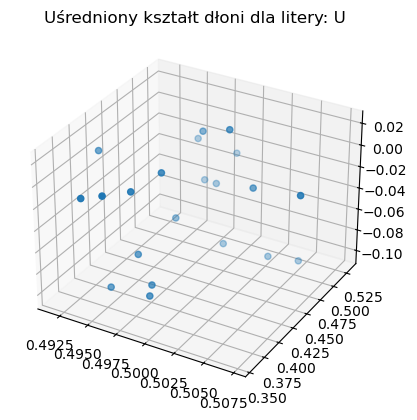

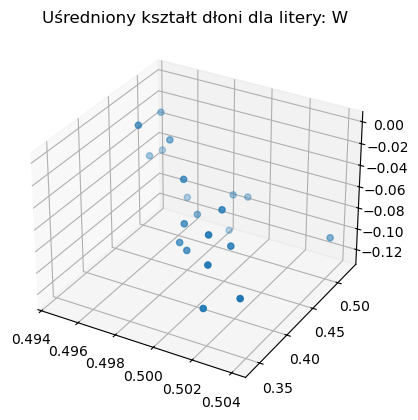

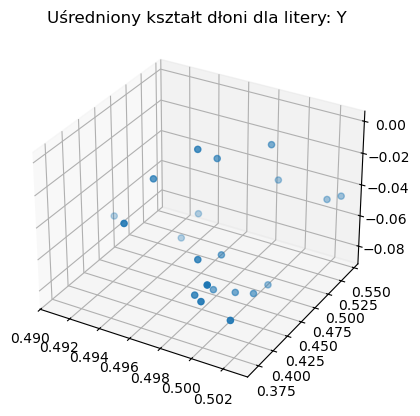

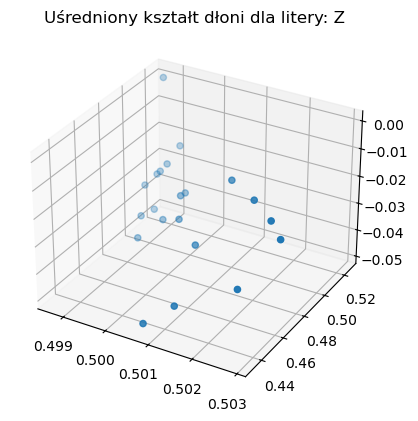

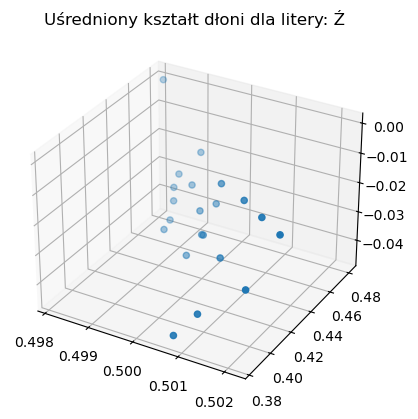

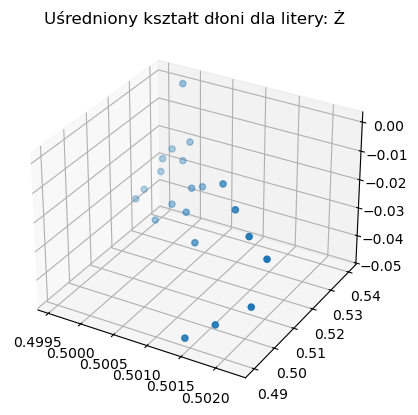

In [ ]:

for letter, points_list in all_points_dict.items():
    mean_shape = np.mean(np.stack(points_list), axis=0).reshape(-1, 3)
    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')
    ax.scatter(mean_shape[:, 0], mean_shape[:, 1], mean_shape[:, 2])
    ax.set_title(f"Uśredniony kształt dłoni dla litery: {letter.upper()}")
    plt.show()


## Dendogram hierarchiczny podobieństwa liter

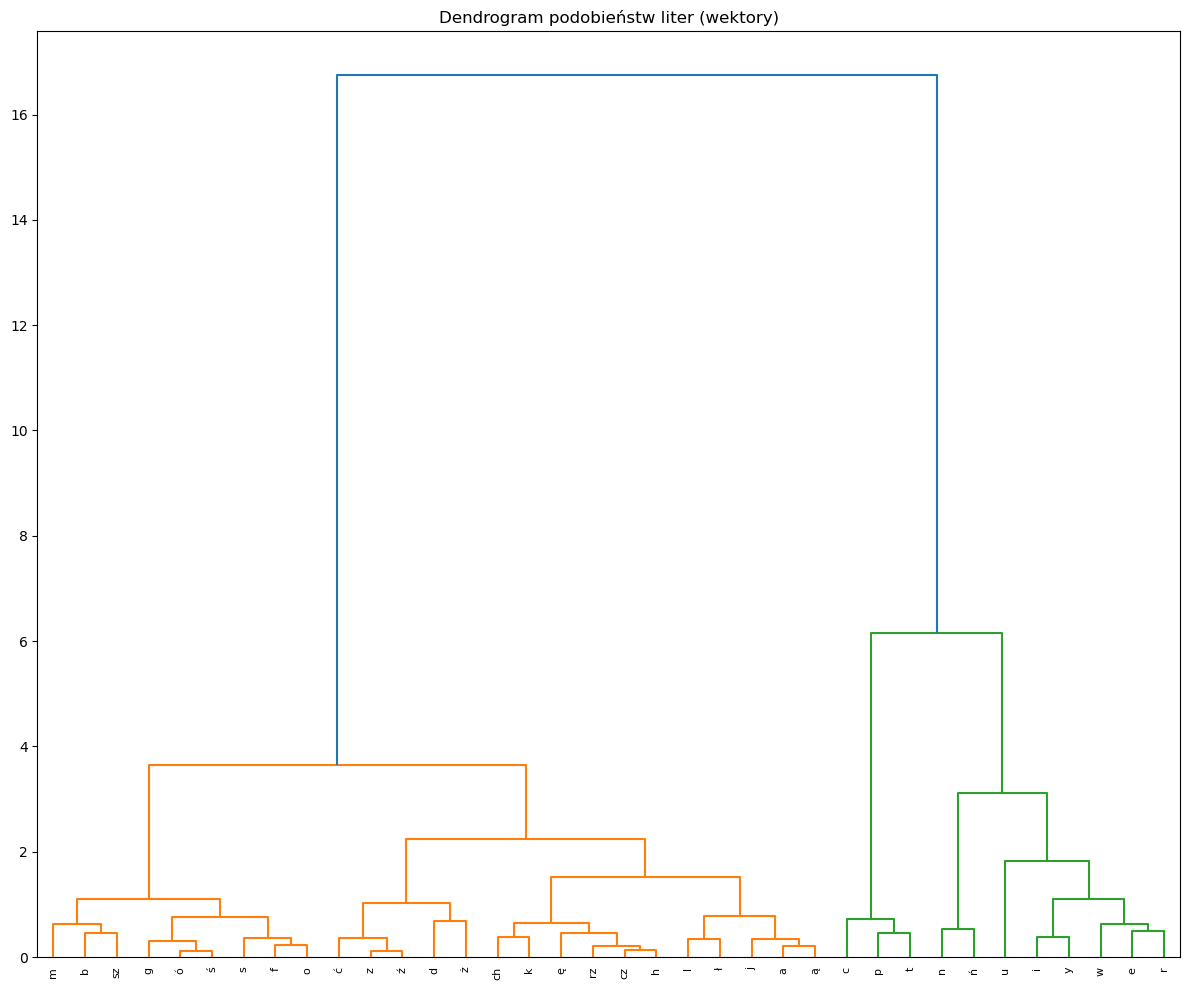

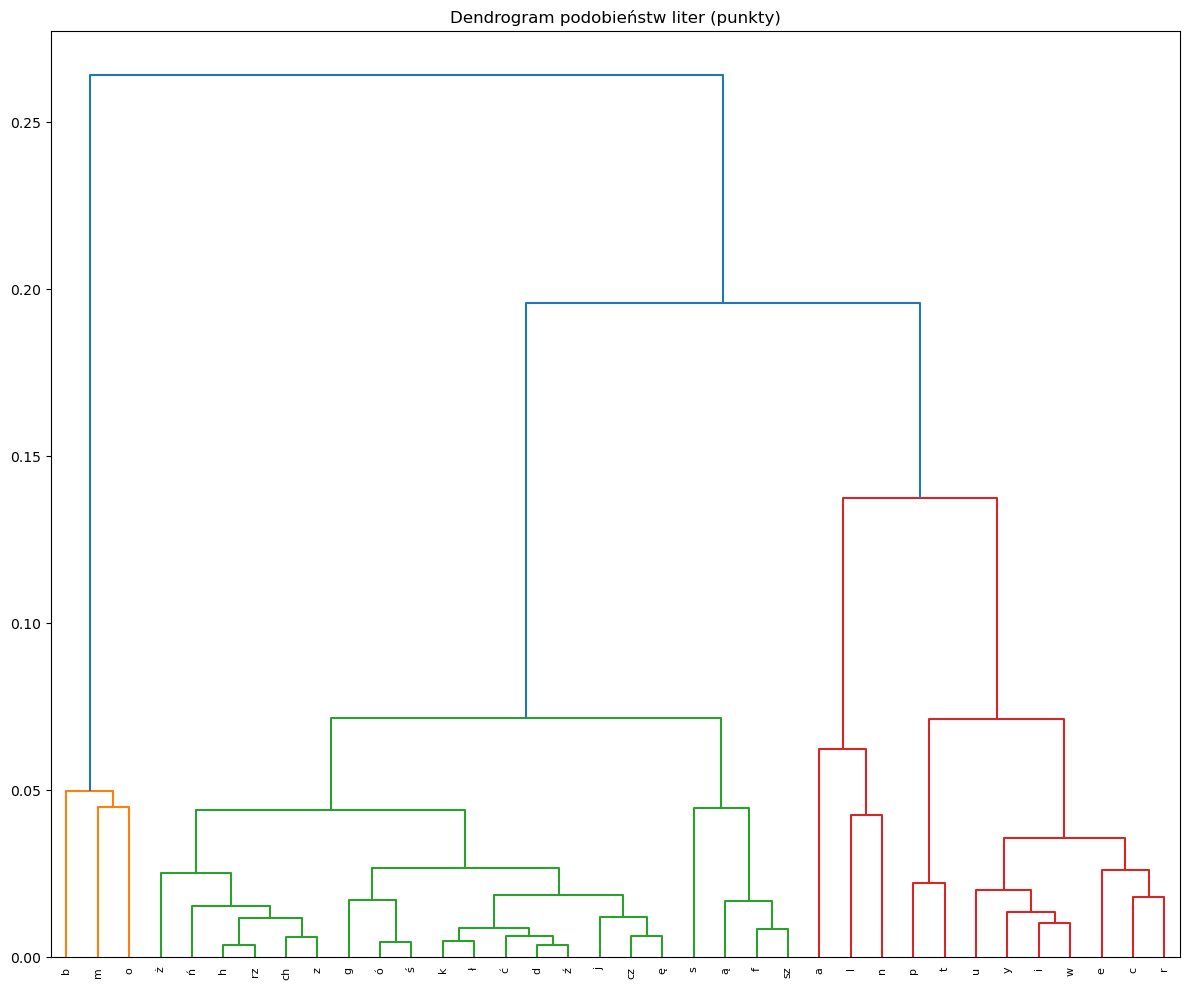

In [66]:
def plot_dendrogram(sim_df, title):
    distance_matrix = 1 - sim_df.values
    linkage_matrix = linkage(distance_matrix, method='ward')
    plt.figure(figsize=(12, 10))
    dendrogram(linkage_matrix, labels=sim_df.index.tolist(), leaf_rotation=90)
    plt.title(title)
    plt.tight_layout()
    plt.show()

plot_dendrogram(vector_sim_df, "Dendrogram podobieństw liter (wektory)")
plot_dendrogram(point_sim_df, "Dendrogram podobieństw liter (punkty)")


## DBSCAN na wektorach
DBSCAN (Density-Based Spatial Clustering of Applications with Noise):
Nie wymaga podania liczby klastrów z góry – liczba grup liter nie jest znana,
Litery, które nie pasują do żadnej grupy, mogą zostać odrzucone,
Wykrywa klastry dowolnego kształtu – przydatne, gdy dane są nierównomiernie rozłożone,
Opiera się na gęstości punktów – idealne, gdy mamy litery reprezentowane jako wektory (cechy z PCA, embeddings itp.), gdzie podobne litery są blisko siebie.


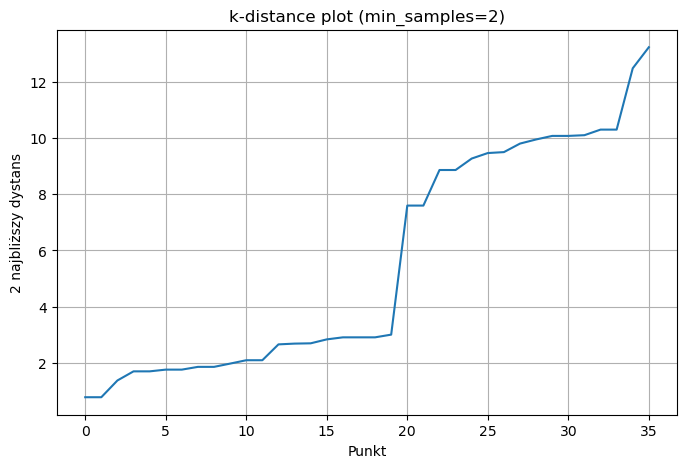

In [72]:
from sklearn.neighbors import NearestNeighbors

vector_array = np.array(list(mean_vectors_dict.values()))
vector_labels = list(mean_vectors_dict.keys())
vector_scaled = StandardScaler().fit_transform(vector_array)

# Parametry DBSCAN
min_samples = 2

# Obliczanie najbliższych sąsiadów
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(vector_scaled)
distances, indices = neighbors_fit.kneighbors(vector_scaled)

# Posortowanie odległości do n-tego sąsiada (czyli pierwszej kolumny)
distances = np.sort(distances[:, min_samples - 1])

# Wykres k-distance
plt.figure(figsize=(8, 5))
plt.plot(distances)
plt.title(f"k-distance plot (min_samples={min_samples})")
plt.xlabel("Punkt")
plt.ylabel(f"{min_samples} najbliższy dystans")
plt.grid(True)
plt.show()

Kolano dla dystansu 3, gwałtowny skok

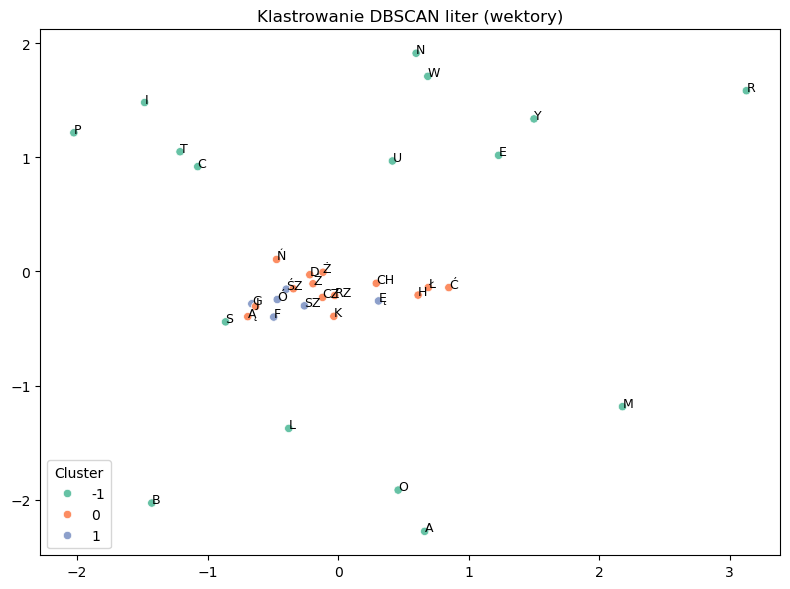

In [103]:
dbscan = DBSCAN(eps=3.2, min_samples=2)  # <- eps dobrany z wykresu
clusters = dbscan.fit_predict(vector_scaled)

# Wizualizacja
plt.figure(figsize=(8, 6))
sns.scatterplot(x=vector_scaled[:, 0], y=vector_scaled[:, 1], hue=clusters, palette='Set2', legend='full')
for i, label in enumerate(vector_labels):
    plt.text(vector_scaled[i, 0], vector_scaled[i, 1], label.upper(), fontsize=9)
plt.title("Klastrowanie DBSCAN liter (wektory)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [104]:
import collections
collections.Counter(clusters)

Counter({-1: 16, 0: 14, 1: 6})

In [84]:
for label, cluster_id in zip(vector_labels, clusters):
    print(f"{label.upper()}: Cluster {cluster_id}")

A: Cluster -1
Ą: Cluster 0
B: Cluster -1
C: Cluster -1
Ć: Cluster 1
CH: Cluster 1
CZ: Cluster 1
D: Cluster 1
E: Cluster -1
Ę: Cluster 2
F: Cluster 2
G: Cluster 2
H: Cluster 1
I: Cluster -1
J: Cluster 0
K: Cluster -1
L: Cluster -1
Ł: Cluster 1
M: Cluster -1
N: Cluster -1
Ń: Cluster 1
O: Cluster -1
Ó: Cluster 2
P: Cluster -1
R: Cluster -1
RZ: Cluster 1
S: Cluster -1
Ś: Cluster 2
SZ: Cluster 2
T: Cluster -1
U: Cluster -1
W: Cluster -1
Y: Cluster -1
Z: Cluster 1
Ź: Cluster 1
Ż: Cluster 1


Wykryto 2 klastry:
Klster 0: 14 liter
Klaster 1: 6 liter
Szum (-1): 16 liter – nieprzypisane do żadnego klastra!

DBSCAN wykrył dwa sensowne skupiska liter, a także odrzucił te bardziej odległe lub rzadkie
Wartość eps = 3.2 na bazie kolana z wykresu wyzej  jest ani za mała (by nie rozbić grup), ani za duża (by nie zlać wszystkiego razem)

## Feature importance z Random Forest


Top feature indices: [49 61 43 28 19 55 10 58  1 52 25 22 46 40 32 37 34 26 16  7]
Top feature importances: [0.04380243 0.03877016 0.0364874  0.03131932 0.03126876 0.02769589
 0.02614299 0.02547973 0.02507886 0.02390762 0.02351777 0.02342098
 0.02322923 0.02314812 0.02279875 0.02196045 0.02064486 0.01892724
 0.01860478 0.01843071]


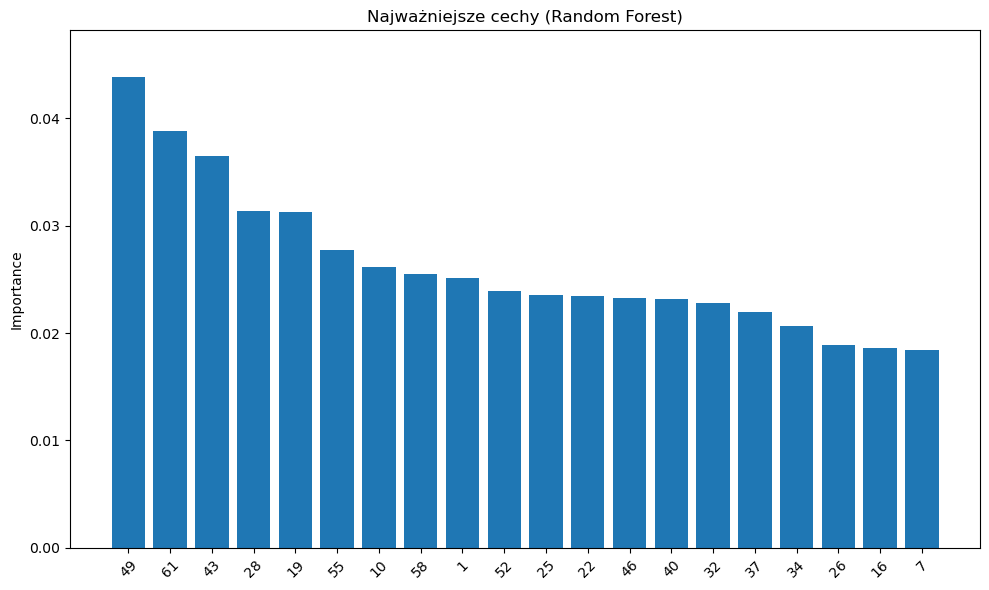

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

X = []
y = []
for label, vectors in all_vectors_dict.items():
    for vec in vectors:
        X.append(vec)
        y.append(label)

X = np.array(X)
y = np.array(y)

rf = RandomForestClassifier(random_state=42)
rf.fit(X, y)

importances = rf.feature_importances_
indices = np.argsort(importances)[-20:][::-1]  

print("Top feature indices:", indices)
print("Top feature importances:", importances[indices])

plt.figure(figsize=(10, 6))
plt.title("Najważniejsze cechy (Random Forest)")
plt.bar(range(len(indices)), importances[indices], align='center')
plt.xticks(range(len(indices)), indices, rotation=45) 
plt.ylabel('Importance')
plt.ylim(0, max(importances[indices]) * 1.1)  
plt.tight_layout()
plt.show()


Top 5 najważniejszych cech (indeksy i ich wagi):

Cecha 49: 0.0438
Cecha 61: 0.0388
Cecha 43: 0.0365
Cecha 28: 0.0313
Cecha 19: 0.0313
Rozkład ważności:
Najwyższa ważność: 0.0438 (Cecha 49), najniższa w top 20: 0.0184 (Cecha 7).

Różnica między cechami jest stosunkowo niewielka (wszystkie wagi mieszczą się w zakresie 0.018–0.044), co sugeruje, że model wykorzystuje wiele cech w podobnym stopniu, bez dominującej pojedynczej cechy.

## Redukcja wymiarów PCA i t-SNE

1. Kluczowe różnice między PCA a t-SNE
Cecha	PCA	t-SNE
Cel	Zachowanie globalnej wariancji	Zachowanie lokalnych podobieństw
Metryka podobieństwa	Odległość euklidesowa	Prawdopodobieństwo sąsiedztwa
Skala odległości	Zachowuje proporcje odległości	Zniekształca odległości globalne
Czułość	Wrażliwe na skale zmiennych	Wrażliwe na parametr perplexity

In [112]:
def plot_dim_reduction(data_dict, method='pca', title_prefix="", color='tab10'):
    data = np.array(list(data_dict.values()))
    labels = list(data_dict.keys())

    if method == 'pca':
        reducer = PCA(n_components=2)
        reduced = reducer.fit_transform(data)
    elif method == 'tsne':
        reducer = TSNE(n_components=2, perplexity=5, random_state=42)
        reduced = reducer.fit_transform(data)
    else:
        raise ValueError("Unsupported method")

    plt.figure(figsize=(12, 10))
    sns.scatterplot(x=reduced[:, 0], y=reduced[:, 1], hue=labels, palette=color)
    for i, label in enumerate(labels):
        plt.text(reduced[i, 0], reduced[i, 1], label.upper(), fontsize=9)
    plt.title(f"{title_prefix} - {method.upper()}")
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

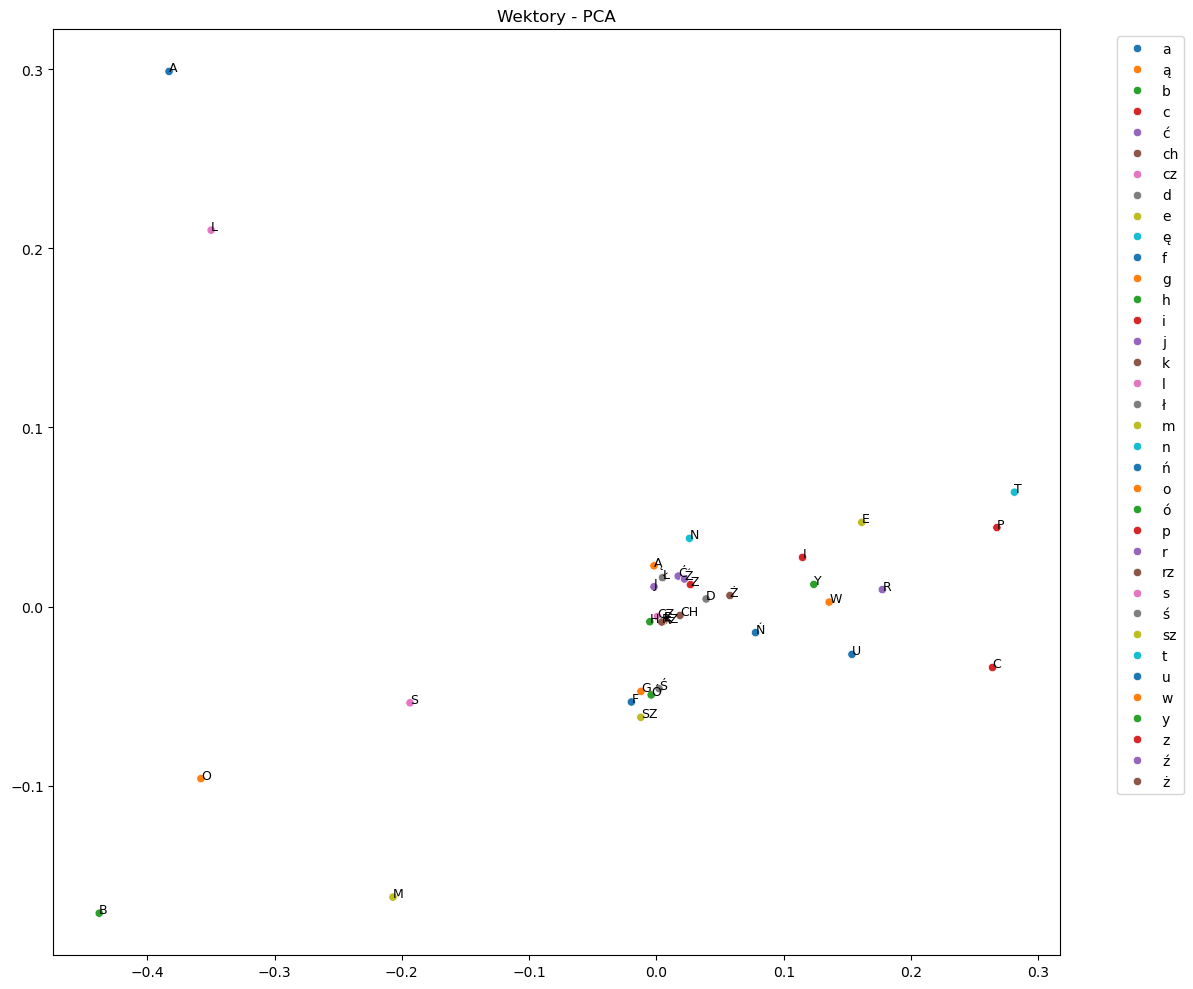

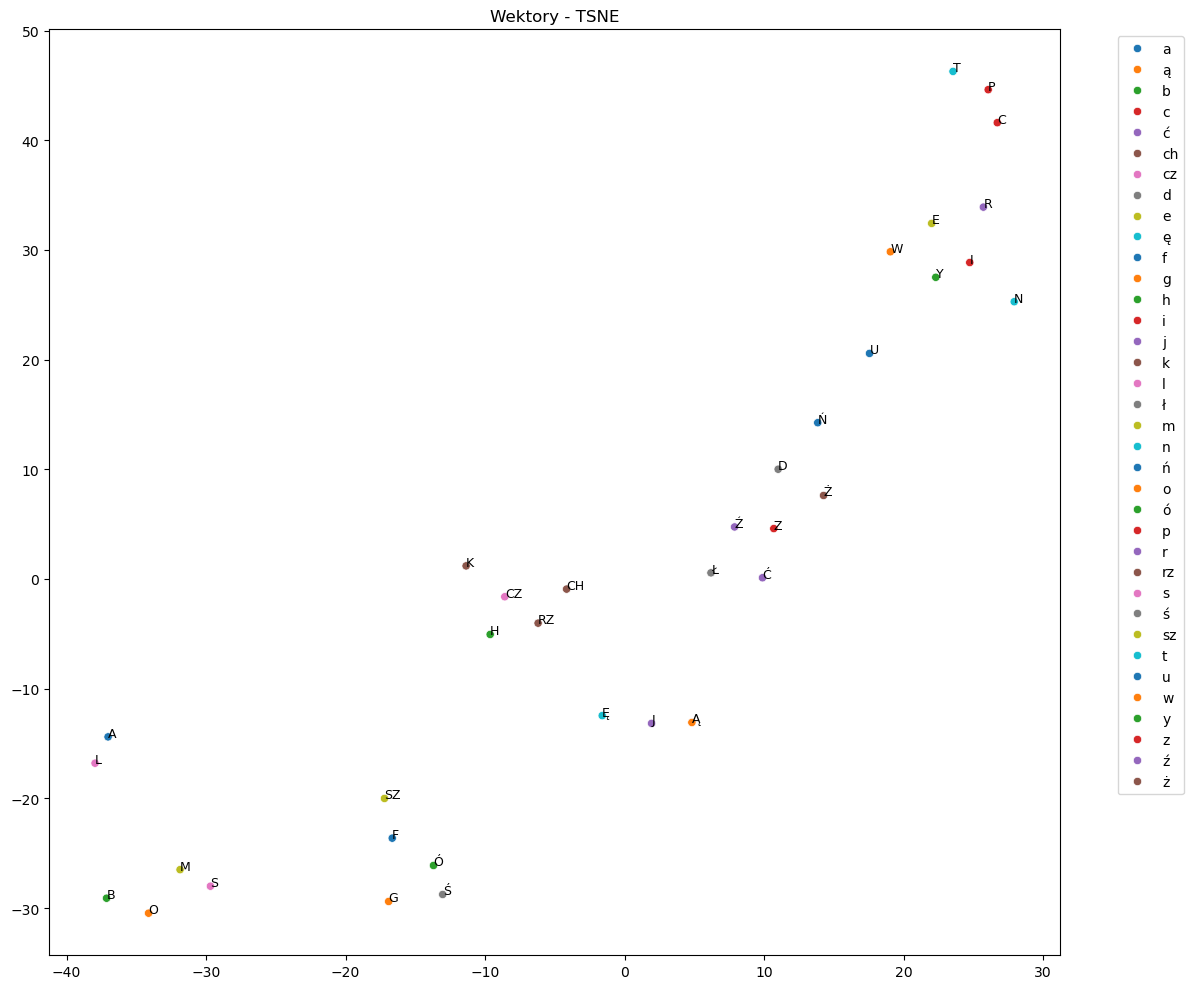

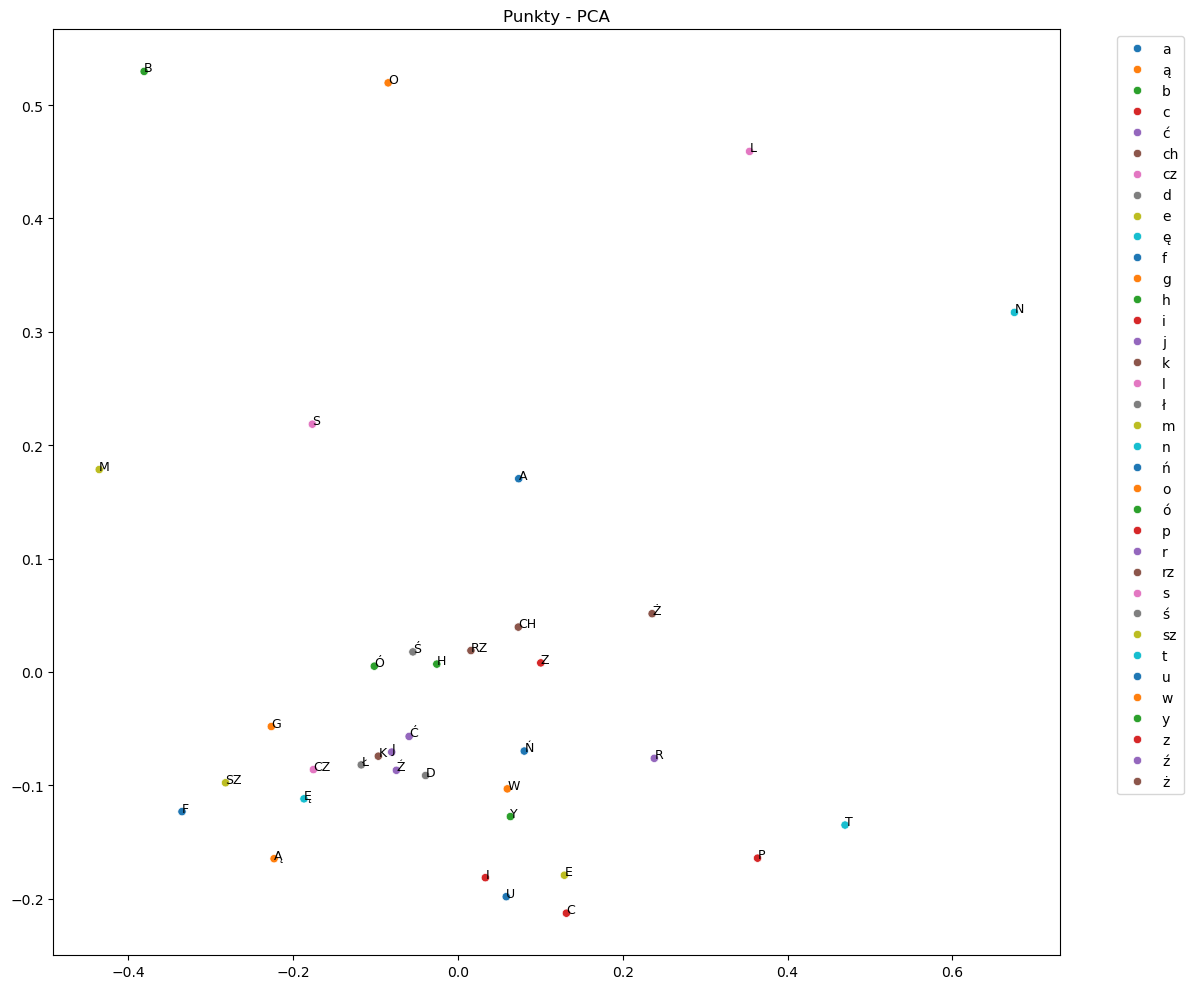

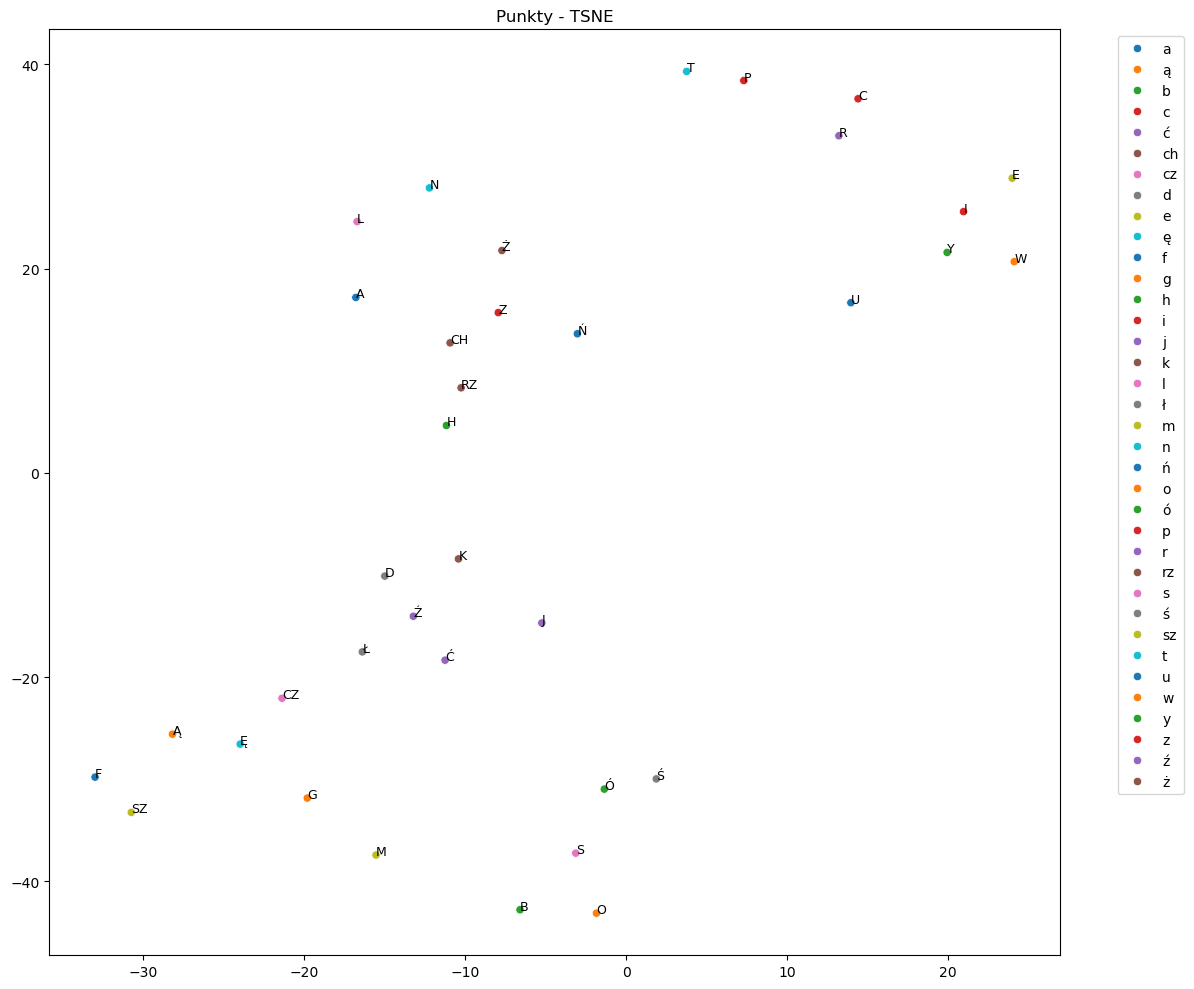

In [113]:
plot_dim_reduction(mean_vectors_dict, method='pca', title_prefix="Wektory")
plot_dim_reduction(mean_vectors_dict, method='tsne', title_prefix="Wektory")
plot_dim_reduction(mean_points_dict, method='pca', title_prefix="Punkty")
plot_dim_reduction(mean_points_dict, method='tsne', title_prefix="Punkty")
